In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib

SEED = 42
N_BOOTSTRAP = 1000
CONFIDENCE_LEVEL = 0.95

OUT = Path("/kaggle/working/S8")
OUT.mkdir(parents=True, exist_ok=True)

print("=== S8: PAIRED BOOTSTRAP ===")

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

print("\nRandom seed:", SEED)
print("Bootstrap iterations:", N_BOOTSTRAP)
print("Confidence level:", CONFIDENCE_LEVEL)

print("\nOutput:", OUT)
print("Mode: SYNTHETIC ONLY")
print("\nS8 ENVIRONMENT: PASS")

=== S8: PAIRED BOOTSTRAP ===
Python: 3.13.18
NumPy: 2.1.3
Pandas: 2.3.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0

Random seed: 42
Bootstrap iterations: 1000
Confidence level: 0.95

Output: /kaggle/working/S8
Mode: SYNTHETIC ONLY

S8 ENVIRONMENT: PASS


In [2]:

# ==========================================
# S8 - CELL 2: SYNTHETIC TEST DATA
# ==========================================

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

SYN_DIR = OUT / "synthetic_inputs"
SYN_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------
# 1. TOY DATASET - HAND-CALCULATED EXAMPLE
# ------------------------------------------

toy_idx = np.arange(4, dtype=np.int64)

toy_y = np.array([1, 0, 1, 0])

toy_a = np.array([0.9, 0.8, 0.7, 0.1])

toy_b = np.array([0.9, 0.6, 0.8, 0.1])

toy_ap_a = average_precision_score(
    toy_y, toy_a
)

toy_ap_b = average_precision_score(
    toy_y, toy_b
)

toy_delta = toy_ap_b - toy_ap_a

assert np.isclose(toy_ap_a, 5 / 6)
assert np.isclose(toy_ap_b, 1.0)
assert np.isclose(toy_delta, 1 / 6)

print("=== TOY DATASET ===")

print("AP A:", round(toy_ap_a, 6))
print("AP B:", round(toy_ap_b, 6))
print("Delta AP:", round(toy_delta, 6))


# Kiểm tra một mẫu bootstrap tính tay
toy_sample = np.array([0, 1, 1, 2])

sample_ap_a = average_precision_score(
    toy_y[toy_sample],
    toy_a[toy_sample]
)

sample_ap_b = average_precision_score(
    toy_y[toy_sample],
    toy_b[toy_sample]
)

sample_delta = sample_ap_b - sample_ap_a

assert np.isclose(sample_ap_a, 0.75)
assert np.isclose(sample_ap_b, 1.0)
assert np.isclose(sample_delta, 0.25)

print("\n=== FIXED BOOTSTRAP SAMPLE ===")
print("Indices:", toy_sample)
print("AP A:", sample_ap_a)
print("AP B:", sample_ap_b)
print("Delta AP:", sample_delta)


# ------------------------------------------
# 2. SYNTHETIC DATASET - 2000 RECORDS
# ------------------------------------------

rng = np.random.default_rng(SEED)

N_SYN = 2000
POS_RATE = 0.14

# ID giả lập, không liên quan đến BRFSS
syn_idx = rng.permutation(
    np.arange(10000, 10000 + N_SYN)
)

# Sinh nhãn mất cân bằng
syn_y = rng.binomial(
    n=1,
    p=POS_RATE,
    size=N_SYN
)

# Sinh nhiễu chung cho hai mô hình
noise = rng.normal(
    loc=0,
    scale=1,
    size=N_SYN
)


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# Điểm dự đoán giả lập
syn_a = sigmoid(
    noise + 0.8 * syn_y - 1.5
)

syn_b = sigmoid(
    noise + 1.1 * syn_y - 1.5
)

# Bản sao chính xác của A
syn_a_copy = syn_a.copy()


# ------------------------------------------
# 3. BASIC VALIDATION
# ------------------------------------------

assert len(np.unique(syn_idx)) == N_SYN
assert set(np.unique(syn_y)) == {0, 1}

for scores in [syn_a, syn_b, syn_a_copy]:

    assert scores.shape == (N_SYN,)
    assert np.isfinite(scores).all()

    assert (
        (scores >= 0) &
        (scores <= 1)
    ).all()

assert np.array_equal(
    syn_a,
    syn_a_copy
)


# ------------------------------------------
# 4. COMPUTE ORIGINAL METRICS
# ------------------------------------------

synthetic_scores = {
    "synthetic_A": syn_a,
    "synthetic_B": syn_b,
    "synthetic_A_copy": syn_a_copy
}

metric_rows = []

for name, scores in synthetic_scores.items():

    metric_rows.append({
        "model": name,
        "AP": average_precision_score(
            syn_y, scores
        ),
        "ROC_AUC": roc_auc_score(
            syn_y, scores
        )
    })

synthetic_metrics = pd.DataFrame(
    metric_rows
)

print("\n=== SYNTHETIC DATASET ===")

print("Records:", N_SYN)
print("Negative:", int((syn_y == 0).sum()))
print("Positive:", int((syn_y == 1).sum()))
print("Positive rate:", round(syn_y.mean(), 6))

print("\n=== SYNTHETIC METRICS ===")

print(
    synthetic_metrics.round(6)
    .to_string(index=False)
)


# ------------------------------------------
# 5. EXPORT TEST FIXTURES
# ------------------------------------------

np.savez_compressed(
    SYN_DIR / "toy_predictions.npz",

    idx_test=toy_idx,
    y_test=toy_y,

    proba_synthetic_A=toy_a,
    proba_synthetic_B=toy_b
)

# Hai file riêng để kiểm thử
# việc ghép cặp giữa các file NPZ

np.savez_compressed(
    SYN_DIR / "synthetic_predictions_A.npz",

    idx_test=syn_idx,
    y_test=syn_y,

    proba_synthetic_A=syn_a,
    proba_synthetic_A_copy=syn_a_copy
)

np.savez_compressed(
    SYN_DIR / "synthetic_predictions_B.npz",

    idx_test=syn_idx,
    y_test=syn_y,

    proba_synthetic_B=syn_b
)

synthetic_metrics.to_csv(
    SYN_DIR / "synthetic_metrics.csv",
    index=False
)

print("\n=== SAVED FILES ===")

for path in sorted(SYN_DIR.iterdir()):

    print(
        path.name,
        "|",
        path.stat().st_size,
        "bytes"
    )

print("\nS8 CELL 2: PASS")


=== TOY DATASET ===
AP A: 0.833333
AP B: 1.0
Delta AP: 0.166667

=== FIXED BOOTSTRAP SAMPLE ===
Indices: [0 1 1 2]
AP A: 0.75
AP B: 1.0
Delta AP: 0.25

=== SYNTHETIC DATASET ===
Records: 2000
Negative: 1713
Positive: 287
Positive rate: 0.1435

=== SYNTHETIC METRICS ===
           model       AP  ROC_AUC
     synthetic_A 0.303357 0.695455
     synthetic_B 0.400630 0.762403
synthetic_A_copy 0.303357 0.695455

=== SAVED FILES ===
synthetic_metrics.csv | 172 bytes
synthetic_predictions_A.npz | 36089 bytes
synthetic_predictions_B.npz | 20745 bytes
toy_predictions.npz | 861 bytes

S8 CELL 2: PASS


In [4]:

%%writefile /kaggle/working/S8/c_bootstrap.py

"""
Paired bootstrap for binary classification.

Primary metric: Average Precision.
Secondary metric: ROC-AUC.

Delta = metric(B) - metric(A).
Confidence interval: percentile bootstrap.
"""

import argparse
import hashlib
import json

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)


# ==========================================
# 1. FILE HASH
# ==========================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()


# ==========================================
# 2. VALIDATE PREDICTION ARRAYS
# ==========================================

def validate_predictions(idx, y, scores):

    if idx.ndim != 1:
        raise ValueError("Index must be 1D")

    if y.ndim != 1 or scores.ndim != 1:
        raise ValueError(
            "Labels and scores must be 1D"
        )

    if not len(idx) == len(y) == len(scores):
        raise ValueError("Length mismatch")

    if len(idx) == 0:
        raise ValueError("Empty dataset")

    if idx.dtype.kind not in "iu":
        raise ValueError("Index must be integer")

    if np.any(idx < 0):
        raise ValueError("Negative index")

    if len(np.unique(idx)) != len(idx):
        raise ValueError("Duplicate row indices")

    if y.dtype.kind not in "biuf":
        raise ValueError("Invalid label dtype")

    if not np.isin(y, [0, 1]).all():
        raise ValueError("Labels must be binary")

    if len(np.unique(y)) != 2:
        raise ValueError("Both classes required")

    if scores.dtype.kind not in "iuf":
        raise ValueError("Invalid score dtype")

    if not np.isfinite(scores).all():
        raise ValueError("Non-finite scores")

    if not (
        (scores >= 0) & (scores <= 1)
    ).all():
        raise ValueError(
            "Scores must be in [0, 1]"
        )


# ==========================================
# 3. LOAD NPZ
# ==========================================

def load_predictions(path, model_name):

    path = Path(path)
    score_key = f"proba_{model_name}"

    required = [
        "idx_test",
        "y_test",
        score_key
    ]

    with np.load(
        path,
        allow_pickle=False
    ) as data:

        missing = [
            key for key in required
            if key not in data.files
        ]

        if missing:
            raise ValueError(
                f"Missing NPZ keys: {missing}"
            )

        idx = data["idx_test"]
        y = data["y_test"]
        scores = data[score_key]

    validate_predictions(idx, y, scores)

    return (
        idx,
        y.astype(np.int64),
        scores.astype(np.float64)
    )


# ==========================================
# 4. VERIFY PAIRED ALIGNMENT
# ==========================================

def load_paired_predictions(
    file_a, model_a,
    file_b, model_b
):

    idx_a, y_a, scores_a = load_predictions(
        file_a, model_a
    )

    idx_b, y_b, scores_b = load_predictions(
        file_b, model_b
    )

    if not np.array_equal(idx_a, idx_b):
        raise ValueError(
            "Row indices or row order mismatch"
        )

    if not np.array_equal(y_a, y_b):
        raise ValueError(
            "Ground-truth labels mismatch"
        )

    return idx_a, y_a, scores_a, scores_b


# ==========================================
# 5. PAIRED BOOTSTRAP CORE
# ==========================================

def paired_bootstrap(
    y,
    scores_a,
    scores_b,
    n_bootstrap=1000,
    seed=42,
    confidence=0.95
):

    y = np.asarray(y)
    scores_a = np.asarray(scores_a)
    scores_b = np.asarray(scores_b)

    n = len(y)
    idx = np.arange(n)

    validate_predictions(idx, y, scores_a)
    validate_predictions(idx, y, scores_b)

    if not isinstance(
        n_bootstrap, (int, np.integer)
    ) or n_bootstrap < 1:
        raise ValueError(
            "n_bootstrap must be positive integer"
        )

    if not 0 < confidence < 1:
        raise ValueError(
            "Confidence must be between 0 and 1"
        )

    rng = np.random.default_rng(seed)

    # Original observed metrics
    observed = {
        "AP": (
            average_precision_score(y, scores_a),
            average_precision_score(y, scores_b)
        ),

        "ROC_AUC": (
            roc_auc_score(y, scores_a),
            roc_auc_score(y, scores_b)
        )
    }

    rows = []

    attempted = 0
    skipped = 0

    max_attempts = n_bootstrap * 100

    while len(rows) < n_bootstrap:

        if attempted >= max_attempts:
            raise RuntimeError(
                "Too many invalid bootstrap samples"
            )

        attempted += 1

        # ONE shared sample for both models
        sample = rng.integers(
            low=0,
            high=n,
            size=n
        )

        y_b = y[sample]

        # Skip samples containing one class
        if np.unique(y_b).size != 2:
            skipped += 1
            continue

        p_a = scores_a[sample]
        p_b = scores_b[sample]

        ap_a = average_precision_score(
            y_b, p_a
        )

        ap_b = average_precision_score(
            y_b, p_b
        )

        auc_a = roc_auc_score(
            y_b, p_a
        )

        auc_b = roc_auc_score(
            y_b, p_b
        )

        rows.append({
            "iteration": len(rows) + 1,

            "AP_A": ap_a,
            "AP_B": ap_b,
            "delta_AP": ap_b - ap_a,

            "ROC_AUC_A": auc_a,
            "ROC_AUC_B": auc_b,
            "delta_ROC_AUC": auc_b - auc_a
        })

    draws = pd.DataFrame(rows)

    # Percentile confidence interval
    alpha = 1 - confidence

    summary_rows = []

    for metric, values in observed.items():

        observed_a, observed_b = values

        delta = draws[
            f"delta_{metric}"
        ].to_numpy()

        ci_lower, ci_upper = np.quantile(
            delta,
            [alpha / 2, 1 - alpha / 2]
        )

        summary_rows.append({
            "metric": metric,

            "observed_A": observed_a,
            "observed_B": observed_b,

            "observed_delta":
                observed_b - observed_a,

            "bootstrap_mean_delta":
                float(delta.mean()),

            "bootstrap_std":
                float(delta.std(ddof=1))
                if len(delta) > 1 else 0.0,

            "ci_lower": float(ci_lower),
            "ci_upper": float(ci_upper),

            "ci_contains_zero": bool(
                ci_lower <= 0 <= ci_upper
            ),

            "confidence": confidence,
            "n_bootstrap": n_bootstrap
        })

    summary = pd.DataFrame(summary_rows)

    metadata = {
        "n_records": n,
        "n_positive": int((y == 1).sum()),
        "n_negative": int((y == 0).sum()),

        "seed": int(seed),

        "n_bootstrap_requested":
            int(n_bootstrap),

        "n_bootstrap_valid": len(draws),
        "n_bootstrap_attempted": attempted,
        "n_bootstrap_skipped": skipped,

        "confidence": float(confidence),
        "ci_method": "percentile",
        "sampling": "paired_row_with_replacement",

        "delta_direction": "B_minus_A",

        "primary_metric": "AP",

        "single_class_policy":
            "skip_and_redraw",

        "model_refitting": False
    }

    return summary, draws, metadata


# ==========================================
# 6. RUN COMPARISON AND SAVE RESULTS
# ==========================================

def run_comparison(
    file_a, model_a,
    file_b, model_b,
    out_dir,
    n_bootstrap=1000,
    seed=42,
    confidence=0.95
):

    idx, y, scores_a, scores_b = (
        load_paired_predictions(
            file_a, model_a,
            file_b, model_b
        )
    )

    summary, draws, metadata = (
        paired_bootstrap(
            y,
            scores_a,
            scores_b,
            n_bootstrap=n_bootstrap,
            seed=seed,
            confidence=confidence
        )
    )

    metadata.update({
        "model_A": model_a,
        "model_B": model_b,

        "file_A": str(file_a),
        "file_B": str(file_b),

        "file_A_sha256":
            sha256_file(file_a),

        "file_B_sha256":
            sha256_file(file_b),

        "index_alignment": "PASS",
        "label_alignment": "PASS"
    })

    summary.insert(0, "model_A", model_a)
    summary.insert(1, "model_B", model_b)

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    summary.to_csv(
        out_dir / "bootstrap_summary.csv",
        index=False
    )

    draws.to_csv(
        out_dir / "bootstrap_draws.csv",
        index=False
    )

    with open(
        out_dir / "bootstrap_metadata.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=2
        )

    return summary, draws, metadata


# ==========================================
# 7. COMMAND-LINE INTERFACE
# ==========================================

def main():

    parser = argparse.ArgumentParser(
        description="Paired bootstrap comparison"
    )

    parser.add_argument(
        "--file-a", required=True
    )

    parser.add_argument(
        "--model-a", required=True
    )

    parser.add_argument(
        "--file-b", required=True
    )

    parser.add_argument(
        "--model-b", required=True
    )

    parser.add_argument(
        "--out-dir", required=True
    )

    parser.add_argument(
        "--n-bootstrap", type=int, default=1000
    )

    parser.add_argument(
        "--seed", type=int, default=42
    )

    parser.add_argument(
        "--confidence", type=float, default=0.95
    )

    args = parser.parse_args()

    summary, draws, metadata = run_comparison(
        file_a=args.file_a,
        model_a=args.model_a,
        file_b=args.file_b,
        model_b=args.model_b,
        out_dir=args.out_dir,
        n_bootstrap=args.n_bootstrap,
        seed=args.seed,
        confidence=args.confidence
    )

    print("\n=== PAIRED BOOTSTRAP SUMMARY ===")

    print(
        summary.round(6).to_string(index=False)
    )

    print("\n=== SAMPLING INFORMATION ===")

    print(
        "Valid:",
        metadata["n_bootstrap_valid"]
    )

    print(
        "Attempted:",
        metadata["n_bootstrap_attempted"]
    )

    print(
        "Skipped:",
        metadata["n_bootstrap_skipped"]
    )


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/S8/c_bootstrap.py


In [5]:

# ==========================================
# S8 - CELL 4: MODULE VALIDATION
# ==========================================

import py_compile
import importlib

BOOTSTRAP_PATH = OUT / "c_bootstrap.py"

# 1. Check source file
assert BOOTSTRAP_PATH.is_file()
assert BOOTSTRAP_PATH.stat().st_size > 0

# 2. Check Python syntax
py_compile.compile(
    str(BOOTSTRAP_PATH),
    doraise=True
)

print("[PASS] Python syntax")


# 3. Import module
if str(OUT) not in sys.path:
    sys.path.insert(0, str(OUT))

import c_bootstrap as cb

cb = importlib.reload(cb)

assert Path(cb.__file__).resolve() == (
    BOOTSTRAP_PATH.resolve()
)

print("[PASS] Module import")


# 4. Check required functions
required_functions = [
    "sha256_file",
    "validate_predictions",
    "load_predictions",
    "load_paired_predictions",
    "paired_bootstrap",
    "run_comparison",
    "main"
]

for name in required_functions:

    assert callable(getattr(cb, name))

    print(f"[PASS] {name}")


# 5. Check paired input loading
idx, y, scores_a, scores_b = (
    cb.load_paired_predictions(
        SYN_DIR / "synthetic_predictions_A.npz",
        "synthetic_A",
        SYN_DIR / "synthetic_predictions_B.npz",
        "synthetic_B"
    )
)

assert np.array_equal(idx, syn_idx)
assert np.array_equal(y, syn_y)
assert np.array_equal(scores_a, syn_a)
assert np.array_equal(scores_b, syn_b)

print("[PASS] Synthetic paired alignment")


# 6. Source information
print("\n=== SOURCE INFORMATION ===")

print("File:", BOOTSTRAP_PATH)
print("Size:", BOOTSTRAP_PATH.stat().st_size)
print("SHA-256:", cb.sha256_file(BOOTSTRAP_PATH))

print("\n=== PAIRED INPUT ===")

print("Records:", len(idx))
print("Positive:", int((y == 1).sum()))
print("Negative:", int((y == 0).sum()))

print("\nS8 CELL 4: PASS")


[PASS] Python syntax
[PASS] Module import
[PASS] sha256_file
[PASS] validate_predictions
[PASS] load_predictions
[PASS] load_paired_predictions
[PASS] paired_bootstrap
[PASS] run_comparison
[PASS] main
[PASS] Synthetic paired alignment

=== SOURCE INFORMATION ===
File: /kaggle/working/S8/c_bootstrap.py
Size: 10630
SHA-256: 9a6923b4b8de3bbae67118de5654b9431742b69702208c044e0f1783f4007143

=== PAIRED INPUT ===
Records: 2000
Positive: 287
Negative: 1713

S8 CELL 4: PASS


In [6]:

# ==========================================
# S8 - CELL 5: PAIRED BOOTSTRAP TESTS
# ==========================================

import json

RESULT_DIR = OUT / "synthetic_results"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

FILE_A = SYN_DIR / "synthetic_predictions_A.npz"
FILE_B = SYN_DIR / "synthetic_predictions_B.npz"

bootstrap_checks = {}

def mark_pass(name):
    bootstrap_checks[name] = "PASS"
    print(f"[PASS] {name}")


# ------------------------------------------
# T01: MODEL A VS MODEL B
# ------------------------------------------

print("=== T01: A VS B ===")

ab_summary, ab_draws, ab_meta = cb.run_comparison(
    file_a=FILE_A,
    model_a="synthetic_A",

    file_b=FILE_B,
    model_b="synthetic_B",

    out_dir=RESULT_DIR / "A_vs_B",

    n_bootstrap=N_BOOTSTRAP,
    seed=SEED,
    confidence=CONFIDENCE_LEVEL
)

assert len(ab_draws) == N_BOOTSTRAP
assert len(ab_summary) == 2

assert ab_meta["n_bootstrap_valid"] == N_BOOTSTRAP

assert (
    ab_meta["n_bootstrap_attempted"]
    == ab_meta["n_bootstrap_valid"]
    + ab_meta["n_bootstrap_skipped"]
)

# Verify original AP
expected_ap_a = average_precision_score(
    syn_y, syn_a
)

expected_ap_b = average_precision_score(
    syn_y, syn_b
)

ap_row = ab_summary[
    ab_summary["metric"] == "AP"
].iloc[0]

assert np.isclose(
    ap_row["observed_A"],
    expected_ap_a
)

assert np.isclose(
    ap_row["observed_B"],
    expected_ap_b
)

assert np.isclose(
    ap_row["observed_delta"],
    expected_ap_b - expected_ap_a
)

# Verify confidence intervals
alpha = 1 - CONFIDENCE_LEVEL

for _, row in ab_summary.iterrows():

    metric = row["metric"]

    delta = ab_draws[
        f"delta_{metric}"
    ].to_numpy()

    expected_ci = np.quantile(
        delta,
        [alpha / 2, 1 - alpha / 2]
    )

    np.testing.assert_allclose(
        [row["ci_lower"], row["ci_upper"]],
        expected_ci,
        rtol=0,
        atol=1e-12
    )

print(
    ab_summary.round(6)
    .to_string(index=False)
)

print("Valid:", ab_meta["n_bootstrap_valid"])
print("Skipped:", ab_meta["n_bootstrap_skipped"])

mark_pass("T01_A_vs_B")


# ------------------------------------------
# T02: MODEL A VS IDENTICAL COPY
# ------------------------------------------

print("\n=== T02: A VS A COPY ===")

aa_summary, aa_draws, aa_meta = cb.run_comparison(
    file_a=FILE_A,
    model_a="synthetic_A",

    file_b=FILE_A,
    model_b="synthetic_A_copy",

    out_dir=RESULT_DIR / "A_vs_A_copy",

    n_bootstrap=N_BOOTSTRAP,
    seed=SEED,
    confidence=CONFIDENCE_LEVEL
)

assert len(aa_draws) == N_BOOTSTRAP

for metric in ["AP", "ROC_AUC"]:

    delta = aa_draws[
        f"delta_{metric}"
    ].to_numpy()

    assert np.all(delta == 0)

for column in [
    "observed_delta",
    "bootstrap_mean_delta",
    "bootstrap_std",
    "ci_lower",
    "ci_upper"
]:

    assert (aa_summary[column] == 0).all()

assert aa_summary["ci_contains_zero"].all()

print(
    aa_summary.round(6)
    .to_string(index=False)
)

mark_pass("T02_identical_models")


# ------------------------------------------
# T03: REVERSE COMPARISON
# ------------------------------------------

print("\n=== T03: B VS A ===")

ba_summary, ba_draws, ba_meta = cb.run_comparison(
    file_a=FILE_B,
    model_a="synthetic_B",

    file_b=FILE_A,
    model_b="synthetic_A",

    out_dir=RESULT_DIR / "B_vs_A",

    n_bootstrap=N_BOOTSTRAP,
    seed=SEED,
    confidence=CONFIDENCE_LEVEL
)

for metric in ["AP", "ROC_AUC"]:

    # Each bootstrap delta must change sign
    np.testing.assert_allclose(
        ba_draws[f"delta_{metric}"],
        -ab_draws[f"delta_{metric}"],
        rtol=0,
        atol=1e-12
    )

    ab = ab_summary[
        ab_summary["metric"] == metric
    ].iloc[0]

    ba = ba_summary[
        ba_summary["metric"] == metric
    ].iloc[0]

    # Observed delta changes sign
    assert np.isclose(
        ba["observed_delta"],
        -ab["observed_delta"],
        rtol=0,
        atol=1e-12
    )

    # CI endpoints reverse
    assert np.isclose(
        ba["ci_lower"],
        -ab["ci_upper"],
        rtol=0,
        atol=1e-12
    )

    assert np.isclose(
        ba["ci_upper"],
        -ab["ci_lower"],
        rtol=0,
        atol=1e-12
    )

print(
    ba_summary.round(6)
    .to_string(index=False)
)

mark_pass("T03_reverse_direction")


# ------------------------------------------
# T04: REPRODUCIBILITY
# ------------------------------------------

print("\n=== T04: SAME SEED ===")

repeat_summary, repeat_draws, repeat_meta = (
    cb.run_comparison(
        file_a=FILE_A,
        model_a="synthetic_A",

        file_b=FILE_B,
        model_b="synthetic_B",

        out_dir=RESULT_DIR / "A_vs_B_repeat",

        n_bootstrap=N_BOOTSTRAP,
        seed=SEED,
        confidence=CONFIDENCE_LEVEL
    )
)

pd.testing.assert_frame_equal(
    ab_draws,
    repeat_draws,
    check_exact=True
)

pd.testing.assert_frame_equal(
    ab_summary,
    repeat_summary,
    check_exact=True
)

assert ab_meta == repeat_meta

print("Bootstrap draws: identical")
print("Summary: identical")
print("Metadata: identical")

mark_pass("T04_seed_reproducibility")


# ------------------------------------------
# T05: TOY DATASET
# ------------------------------------------

print("\n=== T05: TOY DATASET ===")

TOY_FILE = SYN_DIR / "toy_predictions.npz"

toy_summary, toy_draws, toy_meta = cb.run_comparison(
    file_a=TOY_FILE,
    model_a="synthetic_A",

    file_b=TOY_FILE,
    model_b="synthetic_B",

    out_dir=RESULT_DIR / "toy_A_vs_B",

    n_bootstrap=N_BOOTSTRAP,
    seed=SEED,
    confidence=CONFIDENCE_LEVEL
)

toy_ap = toy_summary[
    toy_summary["metric"] == "AP"
].iloc[0]

assert np.isclose(
    toy_ap["observed_A"], 5 / 6
)

assert np.isclose(
    toy_ap["observed_B"], 1
)

assert np.isclose(
    toy_ap["observed_delta"], 1 / 6
)

assert toy_meta["n_bootstrap_valid"] == 1000

assert toy_meta["n_bootstrap_skipped"] > 0

assert (
    toy_meta["n_bootstrap_attempted"]
    == toy_meta["n_bootstrap_valid"]
    + toy_meta["n_bootstrap_skipped"]
)

assert np.isfinite(
    toy_draws.to_numpy()
).all()

print(
    toy_summary.round(6)
    .to_string(index=False)
)

print("Valid:", toy_meta["n_bootstrap_valid"])
print("Attempted:", toy_meta["n_bootstrap_attempted"])
print("Skipped:", toy_meta["n_bootstrap_skipped"])

mark_pass("T05_single_class_handling")


# ------------------------------------------
# SAVE CONSOLIDATED RESULTS
# ------------------------------------------

all_bootstrap_summary = pd.concat(
    [
        ab_summary.assign(comparison="A_vs_B"),
        aa_summary.assign(comparison="A_vs_A_copy"),
        ba_summary.assign(comparison="B_vs_A"),
        toy_summary.assign(comparison="toy_A_vs_B")
    ],
    ignore_index=True
)

all_bootstrap_summary.to_csv(
    RESULT_DIR / "all_bootstrap_summary.csv",
    index=False
)

with open(
    RESULT_DIR / "bootstrap_test_checks.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        bootstrap_checks,
        f,
        indent=2
    )


# ------------------------------------------
# FINAL SUMMARY
# ------------------------------------------

assert len(bootstrap_checks) == 5

assert all(
    status == "PASS"
    for status in bootstrap_checks.values()
)

print("\n=== BOOTSTRAP TEST SUMMARY ===")

for name, status in bootstrap_checks.items():
    print(name, ":", status)

print("\nTests passed:", len(bootstrap_checks), "/ 5")
print("Output:", RESULT_DIR)

print("\nS8 CELL 5: PASS")


=== T01: A VS B ===
    model_A     model_B  metric  observed_A  observed_B  observed_delta  bootstrap_mean_delta  bootstrap_std  ci_lower  ci_upper  ci_contains_zero  confidence  n_bootstrap
synthetic_A synthetic_B      AP    0.303357    0.400630        0.097273              0.096503       0.005849  0.084287  0.107945             False        0.95         1000
synthetic_A synthetic_B ROC_AUC    0.695455    0.762403        0.066949              0.067063       0.002646  0.062025  0.072349             False        0.95         1000
Valid: 1000
Skipped: 0
[PASS] T01_A_vs_B

=== T02: A VS A COPY ===
    model_A          model_B  metric  observed_A  observed_B  observed_delta  bootstrap_mean_delta  bootstrap_std  ci_lower  ci_upper  ci_contains_zero  confidence  n_bootstrap
synthetic_A synthetic_A_copy      AP    0.303357    0.303357             0.0                   0.0            0.0       0.0       0.0              True        0.95         1000
synthetic_A synthetic_A_copy ROC_AUC    0.6

In [7]:

%%writefile /kaggle/working/S8/c_make_figures.py

"""
Visualization for paired binary classification.
Creates PR, ROC, bootstrap distribution and CI plots.
"""

import argparse
import json
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    average_precision_score,
    roc_auc_score
)

from c_bootstrap import (
    load_paired_predictions,
    sha256_file
)


# ==========================================
# 1. SAVE FIGURE
# ==========================================

def save_figure(fig, path):

    fig.tight_layout()

    fig.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    return Path(path)


# ==========================================
# 2. PRECISION-RECALL CURVE
# ==========================================

def plot_pr_curve(
    y, scores_a, scores_b,
    model_a, model_b,
    path, scope
):

    fig, ax = plt.subplots(figsize=(8, 6))

    for name, scores in [
        (model_a, scores_a),
        (model_b, scores_b)
    ]:

        precision, recall, _ = (
            precision_recall_curve(y, scores)
        )

        ap = average_precision_score(y, scores)

        ax.step(
            recall,
            precision,
            where="post",
            label=f"{name} (AP={ap:.4f})"
        )

    prevalence = float(np.mean(y))

    ax.axhline(
        prevalence,
        linestyle="--",
        label=f"No skill ({prevalence:.4f})"
    )

    ax.set(
        xlabel="Recall",
        ylabel="Precision",
        xlim=(0, 1),
        ylim=(0, 1.05),
        title=f"{scope} - Precision-Recall Curve"
    )

    ax.legend()
    ax.grid(alpha=0.2)

    return save_figure(fig, path)


# ==========================================
# 3. ROC CURVE
# ==========================================

def plot_roc_curve(
    y, scores_a, scores_b,
    model_a, model_b,
    path, scope
):

    fig, ax = plt.subplots(figsize=(8, 6))

    for name, scores in [
        (model_a, scores_a),
        (model_b, scores_b)
    ]:

        fpr, tpr, _ = roc_curve(y, scores)

        auc = roc_auc_score(y, scores)

        ax.plot(
            fpr,
            tpr,
            label=f"{name} (AUC={auc:.4f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random classifier"
    )

    ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        xlim=(0, 1),
        ylim=(0, 1.05),
        title=f"{scope} - ROC Curve"
    )

    ax.legend(loc="lower right")
    ax.grid(alpha=0.2)

    return save_figure(fig, path)


# ==========================================
# 4. BOOTSTRAP DISTRIBUTION
# ==========================================

def plot_bootstrap_distribution(
    draws, summary, path, scope
):

    ap_row = summary.loc[
        summary["metric"] == "AP"
    ].iloc[0]

    delta = draws["delta_AP"].to_numpy()

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.hist(
        delta,
        bins=40,
        alpha=0.8,
        edgecolor="white"
    )

    ax.axvline(
        ap_row["observed_delta"],
        linewidth=2,
        label="Observed delta"
    )

    ax.axvline(
        ap_row["ci_lower"],
        linestyle="--",
        label="Lower CI"
    )

    ax.axvline(
        ap_row["ci_upper"],
        linestyle="--",
        label="Upper CI"
    )

    ax.set(
        xlabel="Delta AP (B - A)",
        ylabel="Frequency",
        title=(
            f"{scope} - Bootstrap Distribution"
            f" (n={len(delta)})"
        )
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.2)

    return save_figure(fig, path)


# ==========================================
# 5. CONFIDENCE INTERVAL PLOT
# ==========================================

def plot_confidence_intervals(
    summary, path, scope
):

    fig, ax = plt.subplots(figsize=(8, 4))

    for i, (_, row) in enumerate(
        summary.iterrows()
    ):

        lower = row["ci_lower"]
        upper = row["ci_upper"]
        observed = row["observed_delta"]

        ax.hlines(
            y=i,
            xmin=lower,
            xmax=upper,
            linewidth=3
        )

        ax.vlines(
            [lower, upper],
            i - 0.08,
            i + 0.08
        )

        ax.scatter(
            observed,
            i,
            s=50,
            zorder=3
        )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_yticks(
        np.arange(len(summary))
    )

    ax.set_yticklabels(
        summary["metric"]
    )

    confidence = float(
        summary["confidence"].iloc[0]
    )

    ax.set(
        xlabel="Observed delta (B - A)",
        title=(
            f"{scope} - "
            f"{confidence:.0%} Bootstrap CI"
        )
    )

    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.margins(x=0.15)

    return save_figure(fig, path)


# ==========================================
# 6. VALIDATE BOOTSTRAP RESULTS
# ==========================================

def validate_results(
    summary, draws, metadata,
    y, scores_a, scores_b
):

    if len(summary) != 2 or set(
        summary["metric"]
    ) != {"AP", "ROC_AUC"}:
        raise ValueError(
            "Invalid summary metrics"
        )

    if len(draws) != metadata[
        "n_bootstrap_valid"
    ]:
        raise ValueError(
            "Bootstrap count mismatch"
        )

    expected_iterations = np.arange(
        1, len(draws) + 1
    )

    np.testing.assert_array_equal(
        draws["iteration"],
        expected_iterations
    )

    confidence = metadata["confidence"]
    alpha = 1 - confidence

    metrics = {
        "AP": average_precision_score,
        "ROC_AUC": roc_auc_score
    }

    for metric, metric_fn in metrics.items():

        row = summary.loc[
            summary["metric"] == metric
        ].iloc[0]

        expected_a = metric_fn(y, scores_a)
        expected_b = metric_fn(y, scores_b)

        np.testing.assert_allclose(
            [
                row["observed_A"],
                row["observed_B"],
                row["observed_delta"]
            ],
            [
                expected_a,
                expected_b,
                expected_b - expected_a
            ],
            rtol=0,
            atol=1e-12
        )

        a = draws[f"{metric}_A"].to_numpy()
        b = draws[f"{metric}_B"].to_numpy()
        delta = draws[
            f"delta_{metric}"
        ].to_numpy()

        for values in [a, b, delta]:

            if not np.isfinite(values).all():
                raise ValueError(
                    "Non-finite bootstrap result"
                )

        np.testing.assert_allclose(
            delta,
            b - a,
            rtol=0,
            atol=1e-12
        )

        expected_ci = np.quantile(
            delta,
            [alpha / 2, 1 - alpha / 2]
        )

        np.testing.assert_allclose(
            [
                row["ci_lower"],
                row["ci_upper"]
            ],
            expected_ci,
            rtol=0,
            atol=1e-12
        )

        if not np.isclose(
            row["confidence"], confidence
        ):
            raise ValueError(
                "Confidence level mismatch"
            )


# ==========================================
# 7. MAIN VISUALIZATION PIPELINE
# ==========================================

def make_figures(
    file_a, model_a,
    file_b, model_b,
    bootstrap_dir,
    out_dir,
    scope
):

    if not isinstance(scope, str) or not scope.strip():
        raise ValueError(
            "Explicit figure scope required"
        )

    idx, y, scores_a, scores_b = (
        load_paired_predictions(
            file_a, model_a,
            file_b, model_b
        )
    )

    bootstrap_dir = Path(bootstrap_dir)

    summary = pd.read_csv(
        bootstrap_dir / "bootstrap_summary.csv"
    )

    draws = pd.read_csv(
        bootstrap_dir / "bootstrap_draws.csv"
    )

    metadata = json.loads(
        (
            bootstrap_dir
            / "bootstrap_metadata.json"
        ).read_text(encoding="utf-8")
    )

    # Verify source identity
    if metadata["file_A_sha256"] != (
        sha256_file(file_a)
    ):
        raise ValueError(
            "Source A hash mismatch"
        )

    if metadata["file_B_sha256"] != (
        sha256_file(file_b)
    ):
        raise ValueError(
            "Source B hash mismatch"
        )

    if (
        metadata["model_A"] != model_a
        or metadata["model_B"] != model_b
    ):
        raise ValueError(
            "Model identity mismatch"
        )

    if not (
        (summary["model_A"] == model_a).all()
        and
        (summary["model_B"] == model_b).all()
    ):
        raise ValueError(
            "Summary model mismatch"
        )

    validate_results(
        summary, draws, metadata,
        y, scores_a, scores_b
    )

    out_dir = Path(out_dir)
    out_dir.mkdir(
        parents=True, exist_ok=True
    )

    files = [
        plot_pr_curve(
            y, scores_a, scores_b,
            model_a, model_b,
            out_dir / "fig_pr_curve.png",
            scope
        ),

        plot_roc_curve(
            y, scores_a, scores_b,
            model_a, model_b,
            out_dir / "fig_roc_curve.png",
            scope
        ),

        plot_bootstrap_distribution(
            draws, summary,
            out_dir / "fig_bootstrap_delta_ap.png",
            scope
        ),

        plot_confidence_intervals(
            summary,
            out_dir / "fig_bootstrap_ci.png",
            scope
        )
    ]

    return files


# ==========================================
# 8. COMMAND-LINE INTERFACE
# ==========================================

def main():

    parser = argparse.ArgumentParser()

    parser.add_argument(
        "--file-a", required=True
    )
    parser.add_argument(
        "--model-a", required=True
    )
    parser.add_argument(
        "--file-b", required=True
    )
    parser.add_argument(
        "--model-b", required=True
    )
    parser.add_argument(
        "--bootstrap-dir", required=True
    )
    parser.add_argument(
        "--out-dir", required=True
    )
    parser.add_argument(
        "--scope", required=True
    )

    args = parser.parse_args()

    files = make_figures(
        file_a=args.file_a,
        model_a=args.model_a,
        file_b=args.file_b,
        model_b=args.model_b,
        bootstrap_dir=args.bootstrap_dir,
        out_dir=args.out_dir,
        scope=args.scope
    )

    print("Generated figures:")

    for path in files:
        print(path)


if __name__ == "__main__":
    main()


Writing /kaggle/working/S8/c_make_figures.py


[PASS] V01_python_syntax
[PASS] V02_module_import
[PASS] V03_generate_four_figures

=== GENERATED FIGURES ===
fig_pr_curve.png | 161045 bytes | (1765, 2370, 4)
fig_roc_curve.png | 189014 bytes | (1765, 2370, 4)
fig_bootstrap_delta_ap.png | 106090 bytes | (1466, 2370, 4)
fig_bootstrap_ci.png | 61929 bytes | (1166, 2370, 4)
[PASS] V04_png_integrity

=== VISUALIZATION QA ===
Tests passed: 4 / 4
Source SHA-256: b3b55d9463cccc86fd44fa6636d21dbe0ddc40786cdb540f06ef9cd9e6abf7ef
Output: /kaggle/working/S8/synthetic_figures

S8 CELL 7: PASS

 fig_pr_curve.png


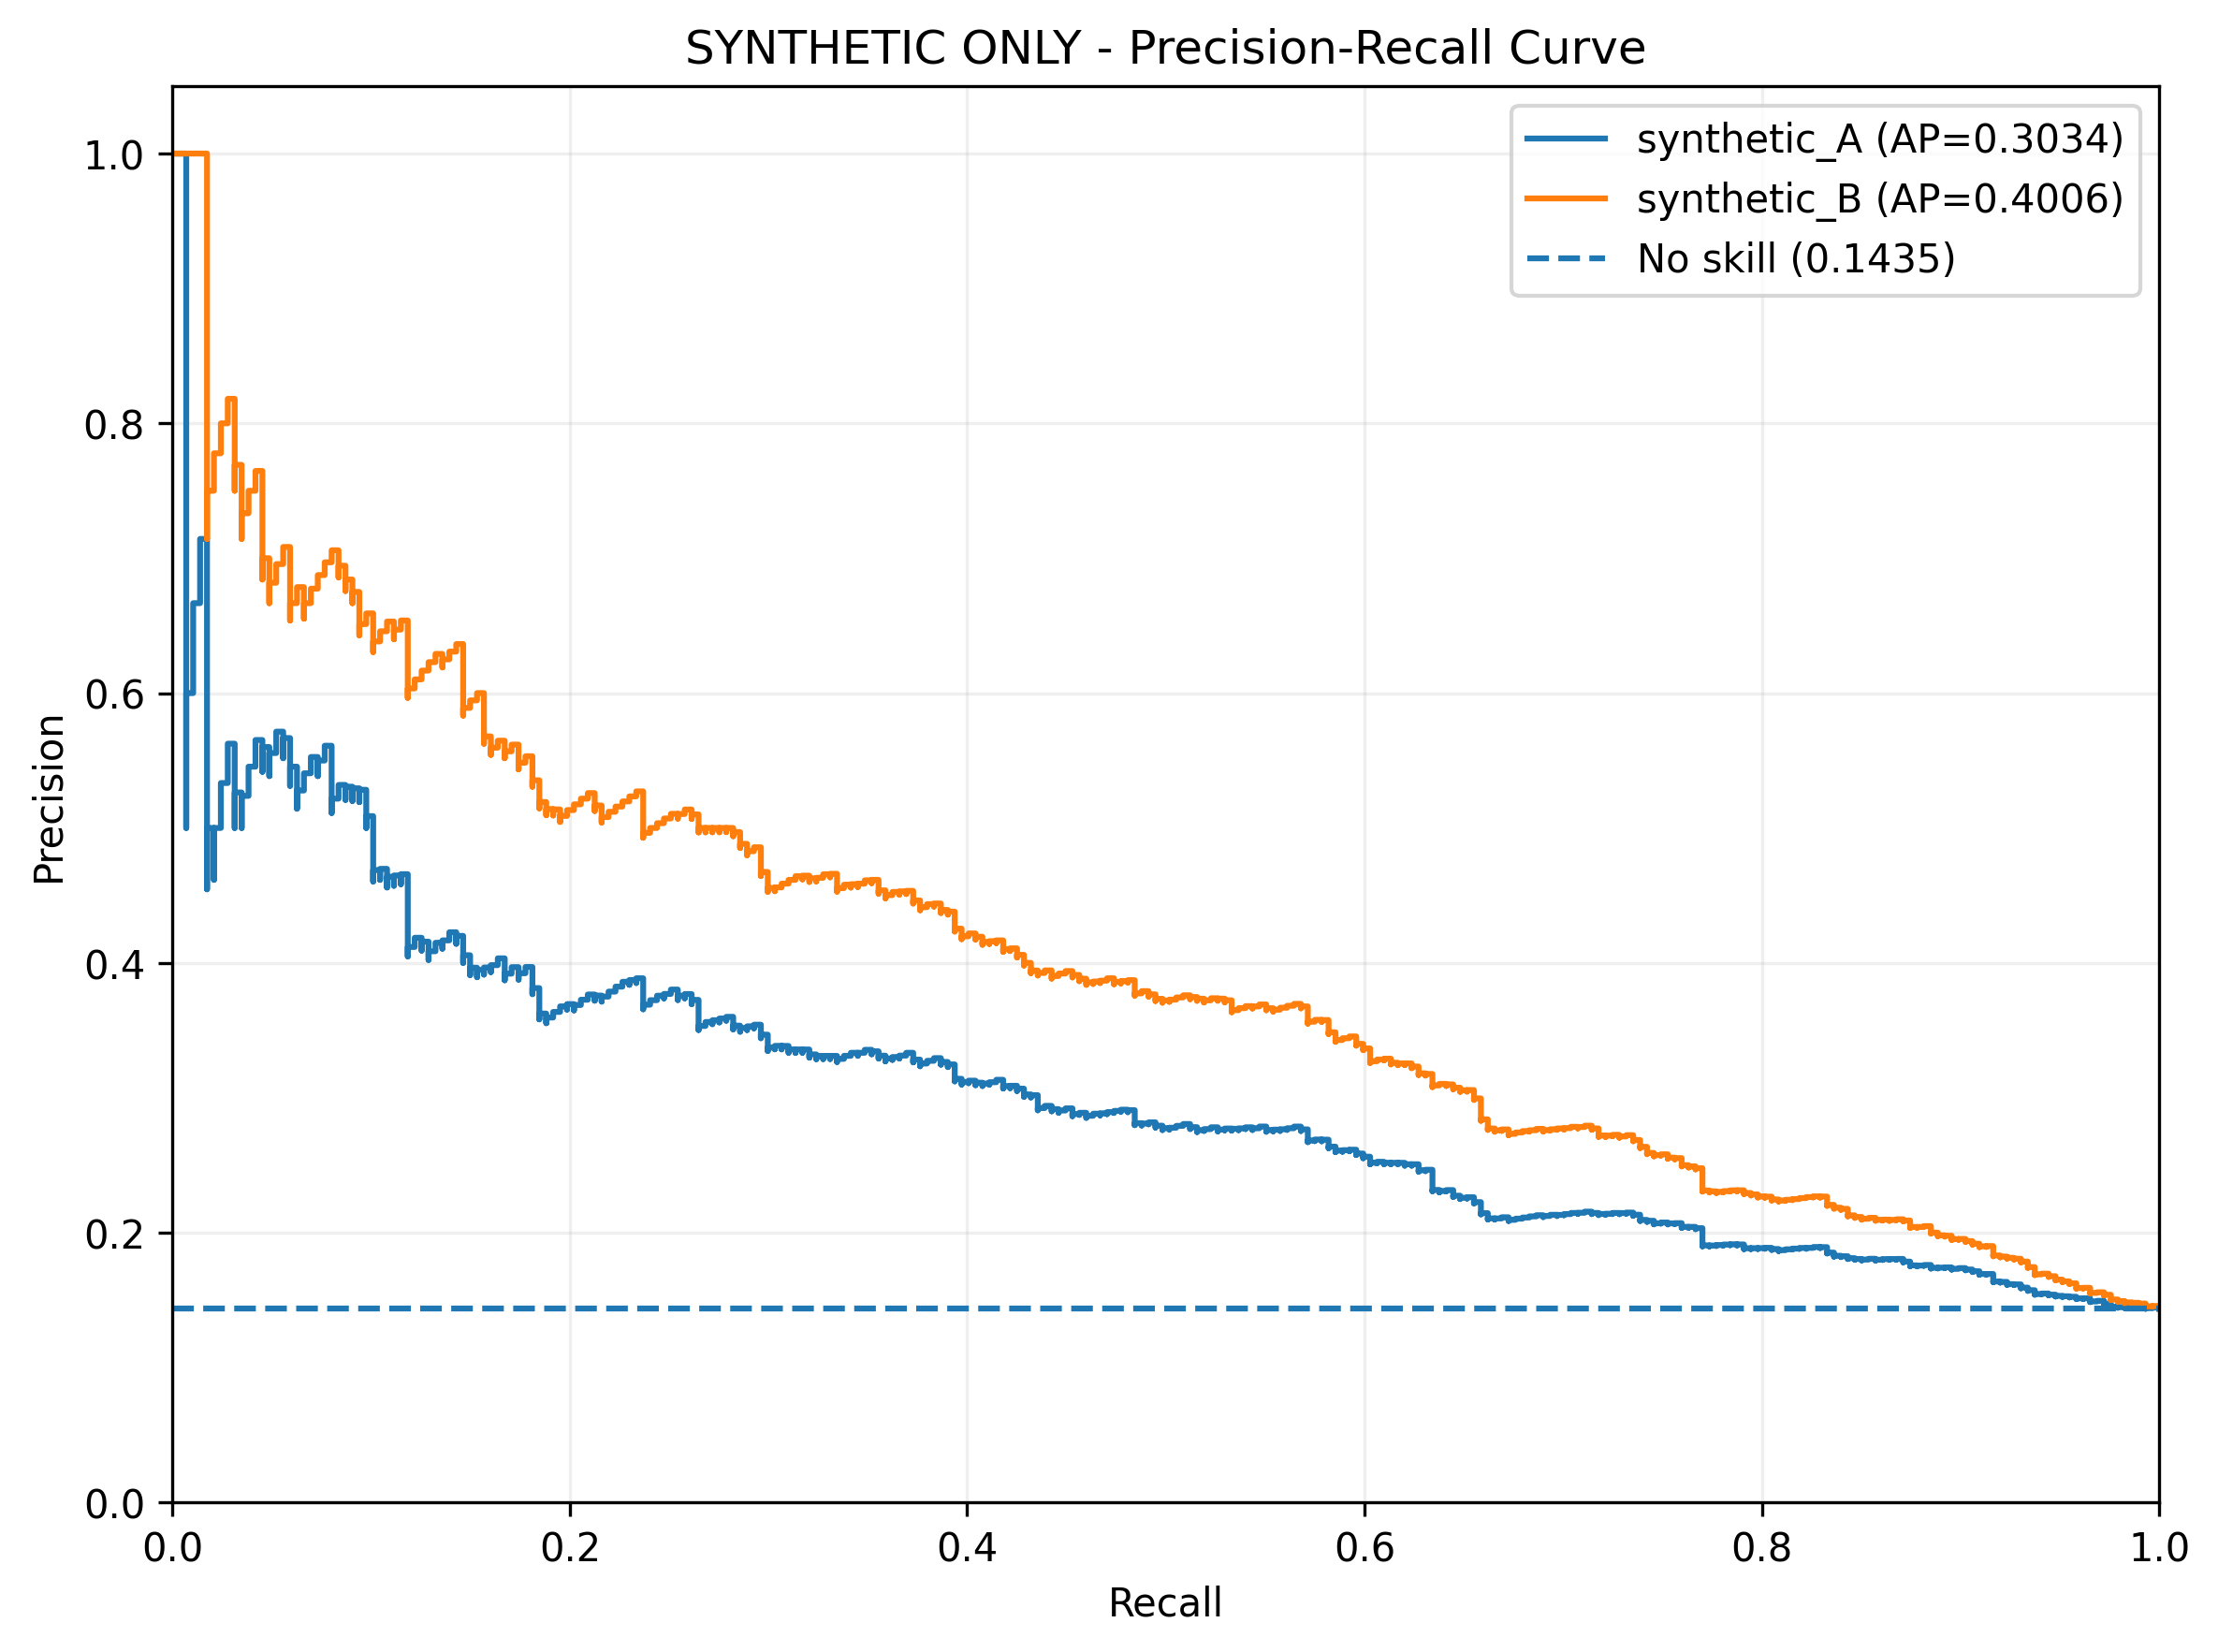


 fig_roc_curve.png


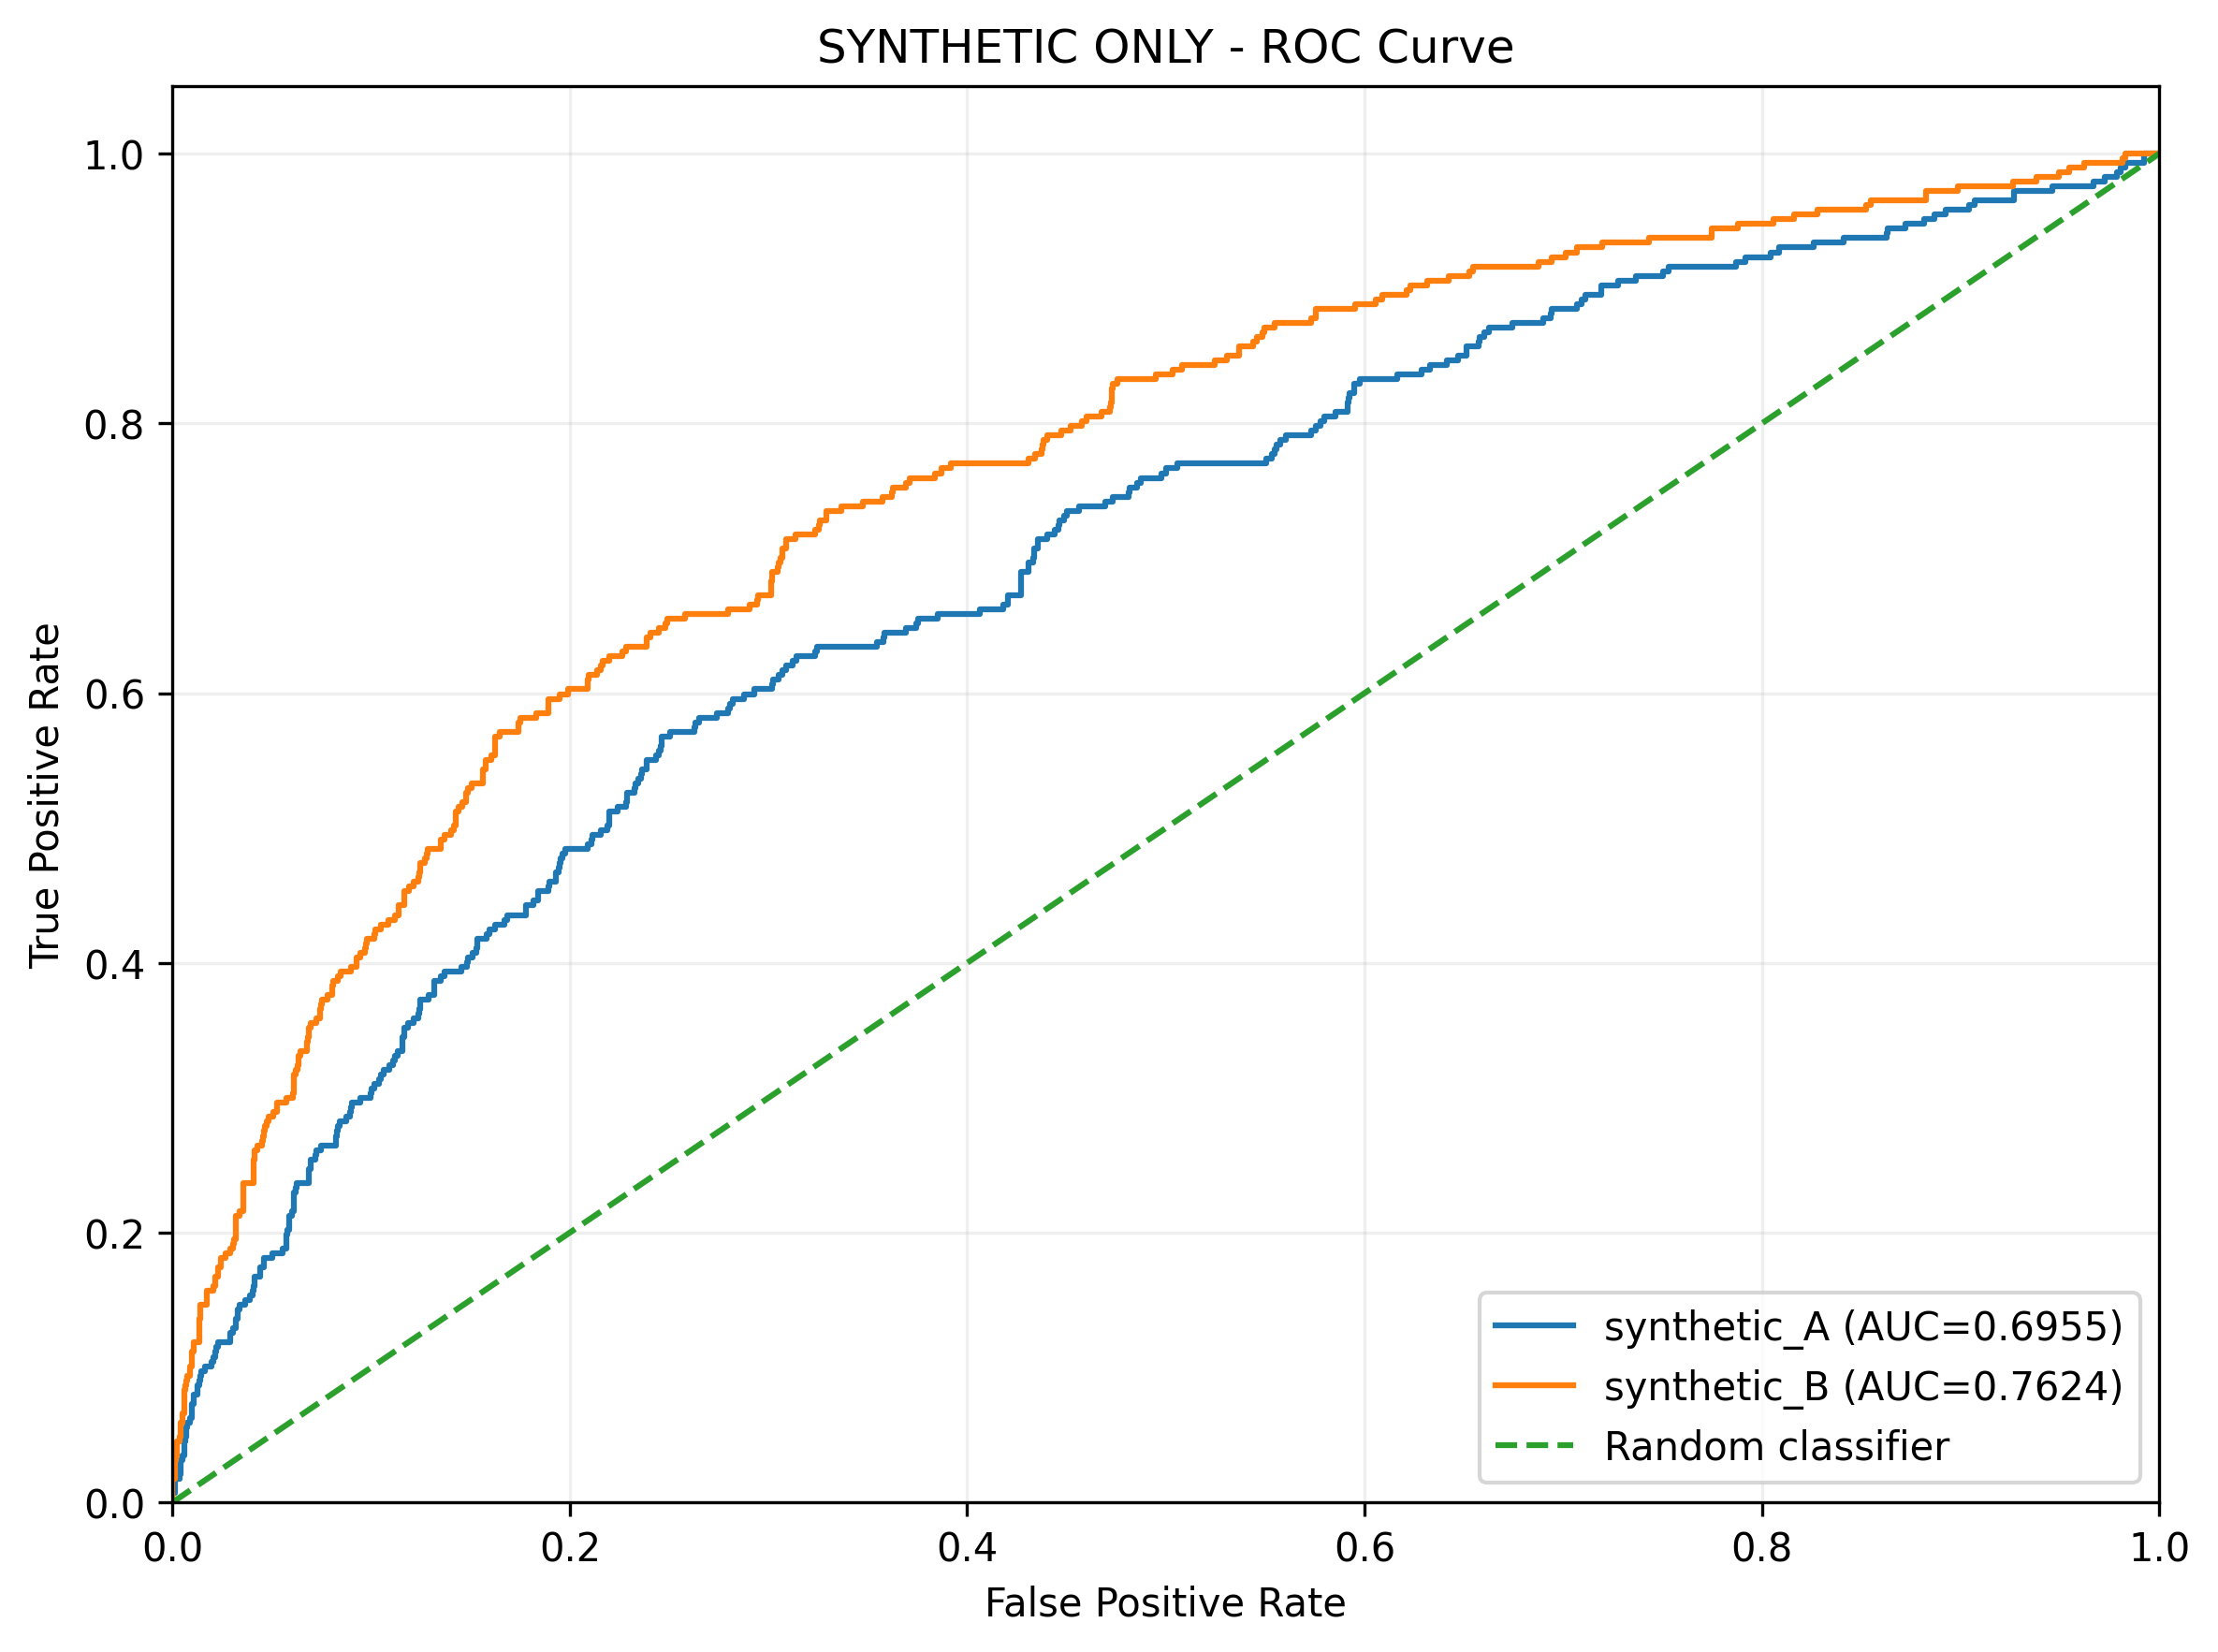


 fig_bootstrap_delta_ap.png


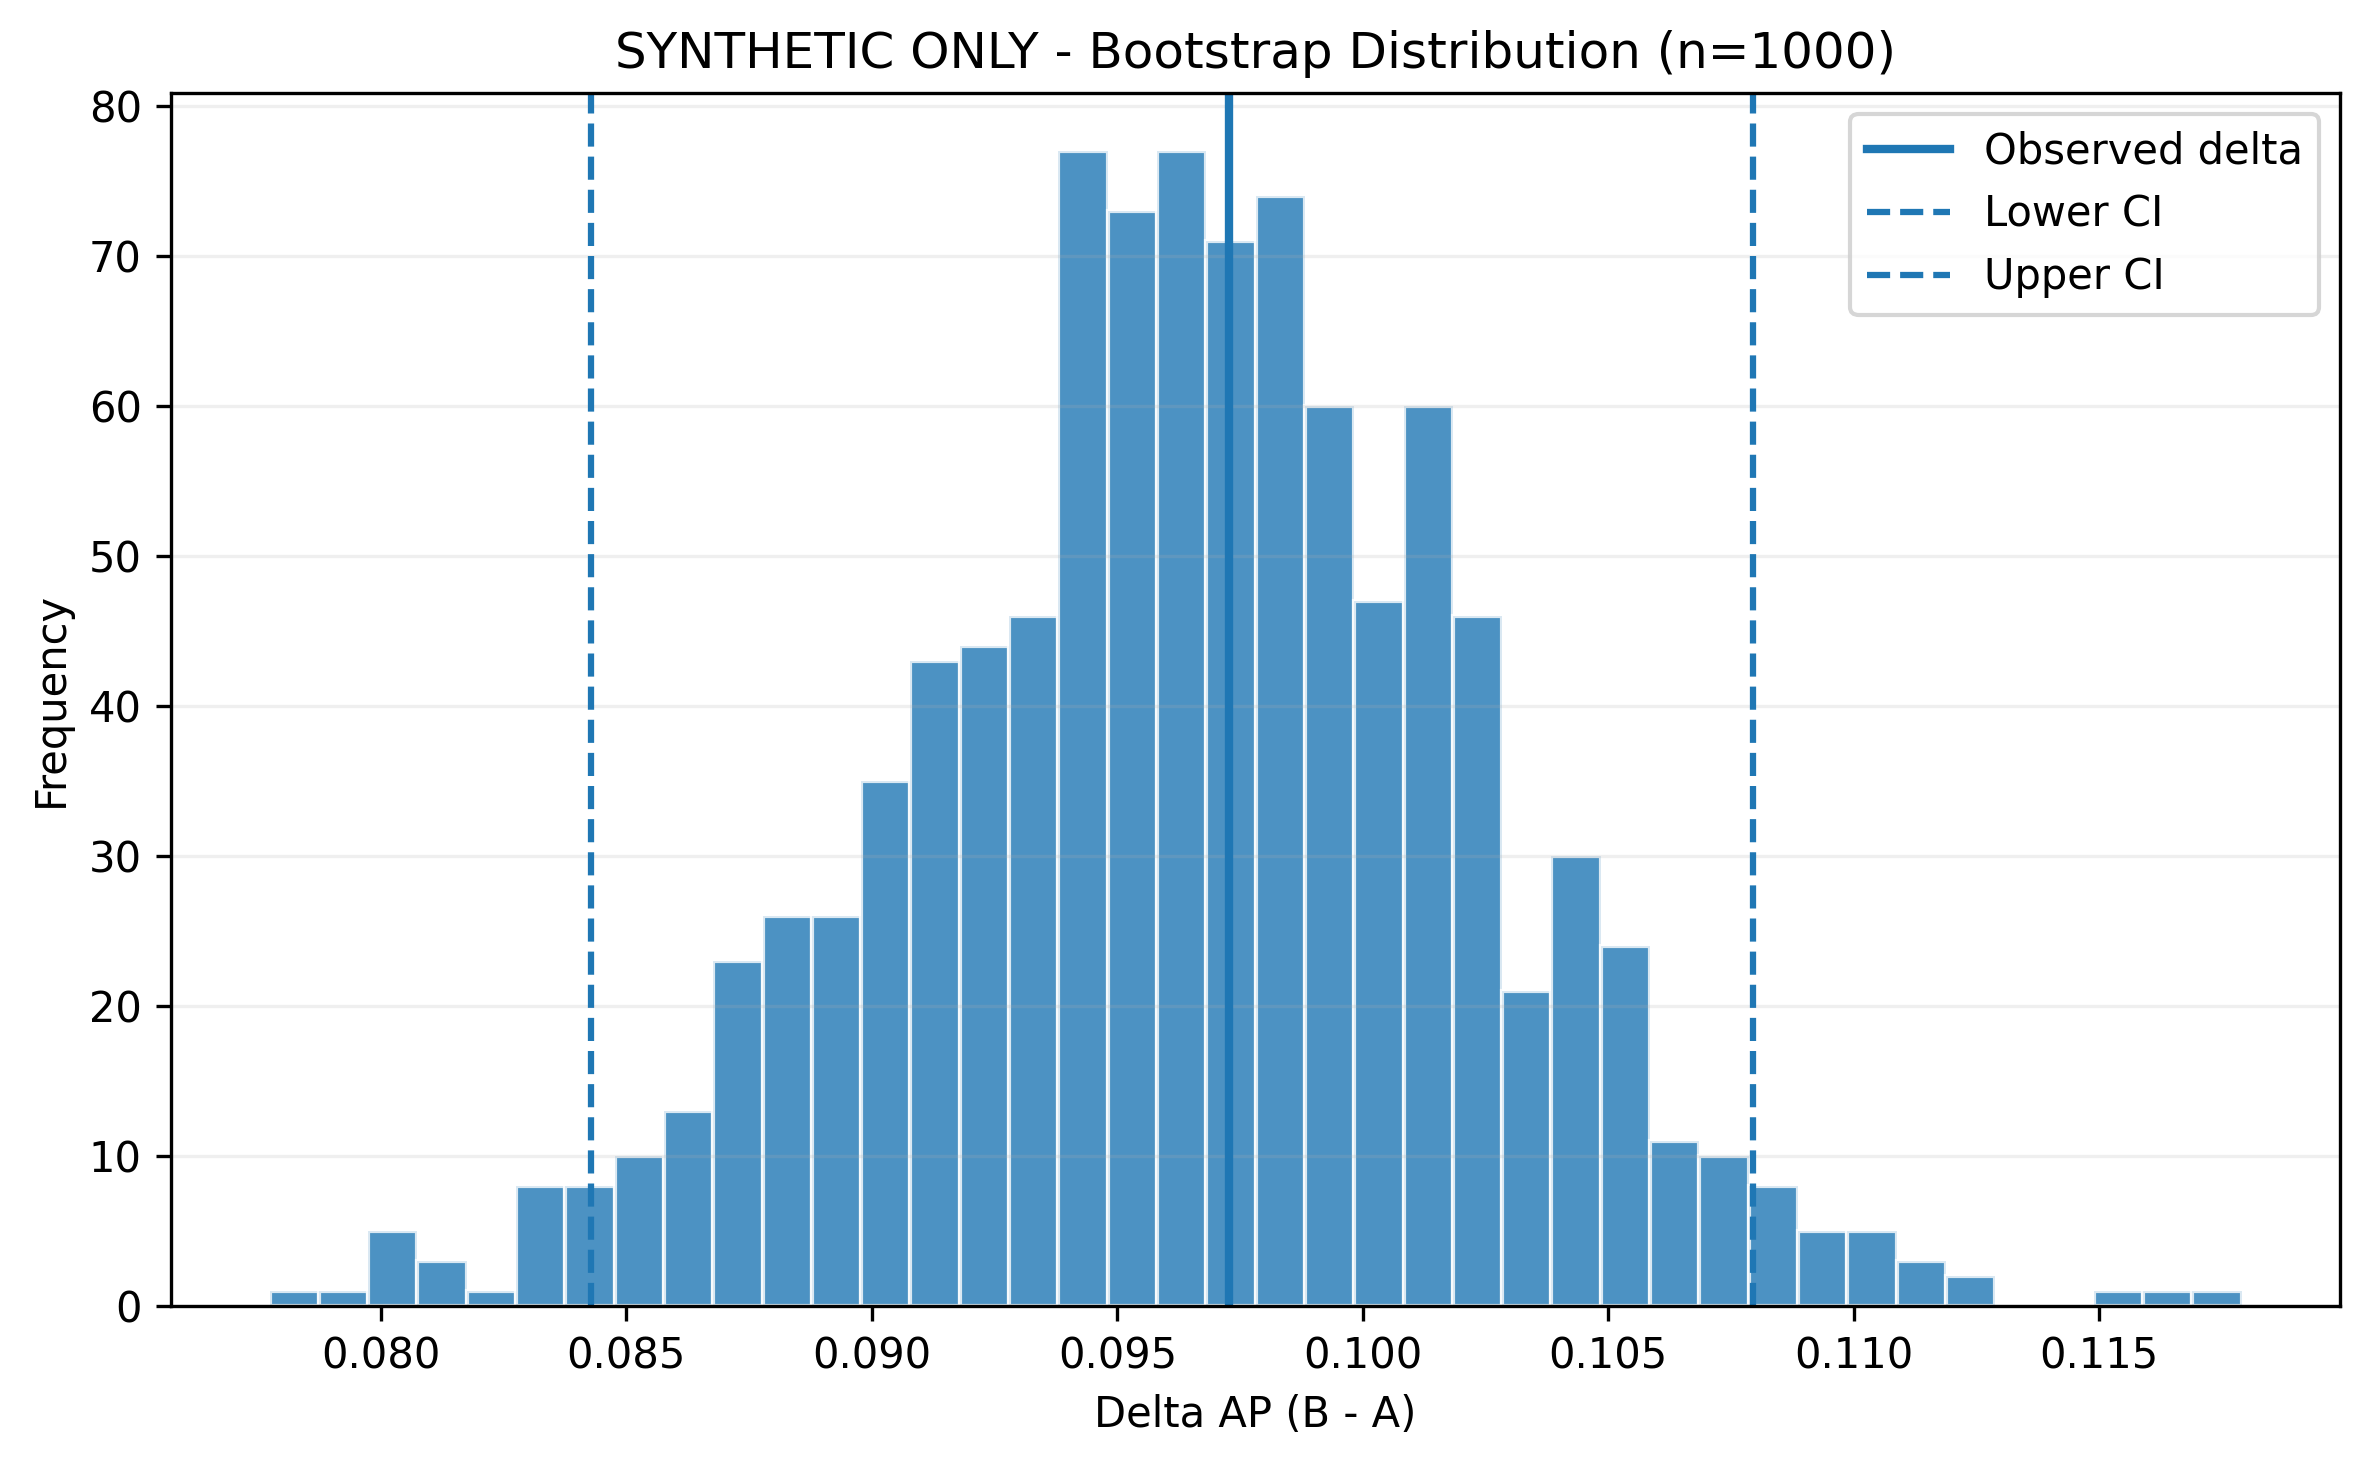


 fig_bootstrap_ci.png


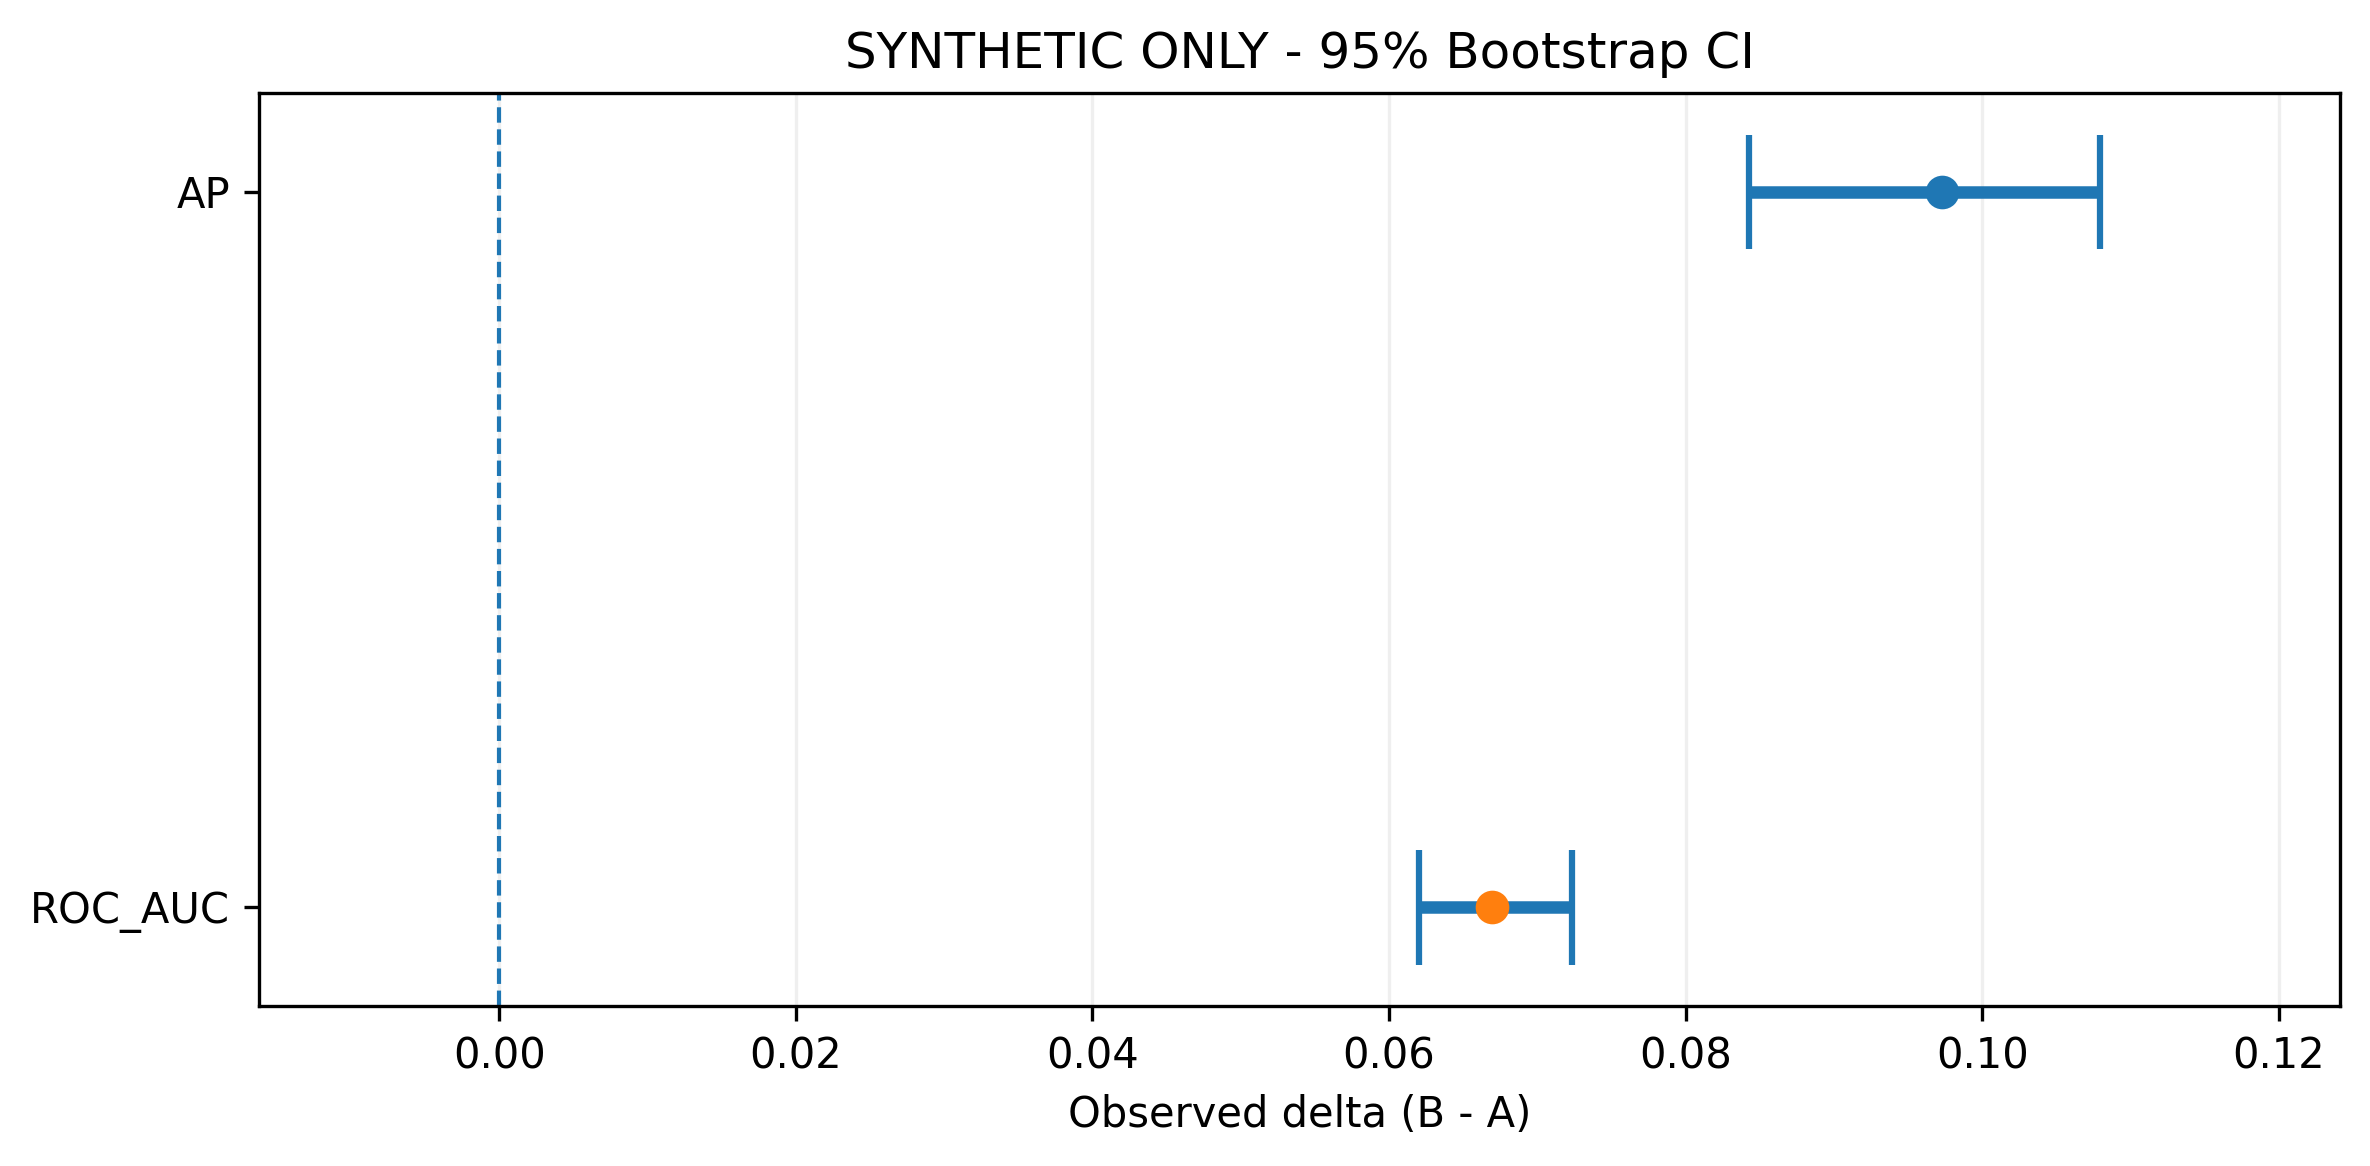

In [9]:

# ==========================================
# S8 - CELL 7: VISUALIZATION TEST
# ==========================================
import matplotlib.pyplot as plt
import py_compile
import importlib

from IPython.display import display, Image

FIGURE_SCRIPT = OUT / "c_make_figures.py"

FIG_DIR = OUT / "synthetic_figures"

figure_checks = {}


def figure_pass(name):

    figure_checks[name] = "PASS"

    print(f"[PASS] {name}")


# ------------------------------------------
# 1. Check syntax
# ------------------------------------------

assert FIGURE_SCRIPT.is_file()

py_compile.compile(
    str(FIGURE_SCRIPT),
    doraise=True
)

figure_pass("V01_python_syntax")


# ------------------------------------------
# 2. Import module
# ------------------------------------------

if str(OUT) not in sys.path:
    sys.path.insert(0, str(OUT))

import c_make_figures as cf

cf = importlib.reload(cf)

assert Path(cf.__file__).resolve() == (
    FIGURE_SCRIPT.resolve()
)

figure_pass("V02_module_import")


# ------------------------------------------
# 3. Generate all four figures
# ------------------------------------------

files = cf.make_figures(
    file_a=FILE_A,
    model_a="synthetic_A",

    file_b=FILE_B,
    model_b="synthetic_B",

    bootstrap_dir=RESULT_DIR / "A_vs_B",

    out_dir=FIG_DIR,

    scope="SYNTHETIC ONLY"
)

assert len(files) == 4

expected_names = {
    "fig_pr_curve.png",
    "fig_roc_curve.png",
    "fig_bootstrap_delta_ap.png",
    "fig_bootstrap_ci.png"
}

assert {
    path.name for path in files
} == expected_names

figure_pass("V03_generate_four_figures")


# ------------------------------------------
# 4. Verify PNG files
# ------------------------------------------

print("\n=== GENERATED FIGURES ===")

for path in files:

    assert path.is_file()
    assert path.stat().st_size > 0

    # PNG file signature
    with open(path, "rb") as f:

        assert f.read(8) == (
            b"\x89PNG\r\n\x1a\n"
        )

    # Verify image can be decoded
    pixels = plt.imread(path)

    assert pixels.ndim in [2, 3]
    assert pixels.shape[0] > 0
    assert pixels.shape[1] > 0

    print(
        path.name,
        "|",
        path.stat().st_size,
        "bytes",
        "|",
        pixels.shape
    )

figure_pass("V04_png_integrity")


# ------------------------------------------
# 5. Save checks
# ------------------------------------------

with open(
    OUT / "figure_test_checks.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        figure_checks,
        f,
        indent=2
    )

assert len(figure_checks) == 4

print("\n=== VISUALIZATION QA ===")

print(
    "Tests passed:",
    len(figure_checks),
    "/ 4"
)

print(
    "Source SHA-256:",
    cb.sha256_file(FIGURE_SCRIPT)
)

print("Output:", FIG_DIR)

print("\nS8 CELL 7: PASS")


# ------------------------------------------
# 6. Display figures
# ------------------------------------------

for path in files:

    print("\n", path.name)

    display(
        Image(
            filename=str(path),
            width=700
        )
    )


In [10]:

# ==========================================
# S8 - CELL 8: ADVANCED QUALITY ASSURANCE
# ==========================================

import shutil
import subprocess
import tempfile
import json

QA_DIR = OUT / "qa"
QA_DIR.mkdir(parents=True, exist_ok=True)

advanced_checks = {}


def qa_pass(name):

    advanced_checks[name] = "PASS"
    print(f"[PASS] {name}")


def expect_error(name, function, error_type, message=None):

    try:
        function()

    except error_type as e:

        if message is not None:
            assert message in str(e), str(e)

        qa_pass(name)

    else:

        raise AssertionError(
            f"{name}: Invalid input was accepted"
        )


# ==========================================
# 1. INVALID INPUT TESTS
# ==========================================

print("=== INVALID INPUT TESTS ===")

with tempfile.TemporaryDirectory() as temp:

    temp = Path(temp)

    def save_bad_npz(
        name,
        idx=syn_idx,
        y=syn_y,
        scores=syn_b
    ):

        path = temp / f"{name}.npz"

        np.savez_compressed(
            path,
            idx_test=idx,
            y_test=y,
            proba_synthetic_B=scores
        )

        return path


    def load_bad(path):

        return cb.load_paired_predictions(
            FILE_A,
            "synthetic_A",
            path,
            "synthetic_B"
        )


    # E01: Wrong row order
    path = save_bad_npz(
        "wrong_order",
        idx=syn_idx[::-1],
        y=syn_y[::-1],
        scores=syn_b[::-1]
    )

    expect_error(
        "E01_wrong_index_order",
        lambda: load_bad(path),
        ValueError,
        "Row indices or row order mismatch"
    )


    # E02: Duplicate index
    bad_idx = syn_idx.copy()
    bad_idx[0] = bad_idx[1]

    path = save_bad_npz(
        "duplicate_index",
        idx=bad_idx
    )

    expect_error(
        "E02_duplicate_index",
        lambda: load_bad(path),
        ValueError,
        "Duplicate row indices"
    )


    # E03: Label mismatch
    bad_y = syn_y.copy()
    bad_y[0] = 1 - bad_y[0]

    path = save_bad_npz(
        "label_mismatch",
        y=bad_y
    )

    expect_error(
        "E03_label_mismatch",
        lambda: load_bad(path),
        ValueError,
        "Ground-truth labels mismatch"
    )


    # E04: Non-binary label
    bad_y = syn_y.copy()
    bad_y[0] = 2

    path = save_bad_npz(
        "invalid_label",
        y=bad_y
    )

    expect_error(
        "E04_non_binary_label",
        lambda: load_bad(path),
        ValueError,
        "Labels must be binary"
    )


    # E05: Single-class input
    path = save_bad_npz(
        "single_class",
        y=np.zeros_like(syn_y)
    )

    expect_error(
        "E05_single_class_input",
        lambda: load_bad(path),
        ValueError,
        "Both classes required"
    )


    # E06: NaN prediction
    bad_scores = syn_b.copy()
    bad_scores[0] = np.nan

    path = save_bad_npz(
        "nan_prediction",
        scores=bad_scores
    )

    expect_error(
        "E06_nan_scores",
        lambda: load_bad(path),
        ValueError,
        "Non-finite scores"
    )


    # E07: Infinity prediction
    bad_scores = syn_b.copy()
    bad_scores[0] = np.inf

    path = save_bad_npz(
        "inf_prediction",
        scores=bad_scores
    )

    expect_error(
        "E07_infinite_scores",
        lambda: load_bad(path),
        ValueError,
        "Non-finite scores"
    )


    # E08: Out-of-range prediction
    bad_scores = syn_b.copy()
    bad_scores[0] = 1.5

    path = save_bad_npz(
        "invalid_probability",
        scores=bad_scores
    )

    expect_error(
        "E08_out_of_range_scores",
        lambda: load_bad(path),
        ValueError,
        "Scores must be in [0, 1]"
    )


    # E09: Different array lengths
    path = save_bad_npz(
        "length_mismatch",
        scores=syn_b[:-1]
    )

    expect_error(
        "E09_length_mismatch",
        lambda: load_bad(path),
        ValueError,
        "Length mismatch"
    )


    # E10: Missing NPZ key
    path = temp / "missing_key.npz"

    np.savez_compressed(
        path,
        y_test=syn_y,
        proba_synthetic_B=syn_b
    )

    expect_error(
        "E10_missing_npz_key",
        lambda: load_bad(path),
        ValueError,
        "Missing NPZ keys"
    )


    # ======================================
    # 2. VISUALIZATION INTEGRITY TESTS
    # ======================================

    print("\n=== VISUALIZATION INTEGRITY ===")

    def generate_figures(
        result_dir,
        file_b=FILE_B,
        model_a="synthetic_A"
    ):

        return cf.make_figures(
            file_a=FILE_A,
            model_a=model_a,

            file_b=file_b,
            model_b="synthetic_B",

            bootstrap_dir=result_dir,
            out_dir=temp / "invalid_figures",

            scope="SYNTHETIC QA"
        )


    # E11: Valid NPZ but changed contents
    bad_scores = syn_b.copy()
    bad_scores[0] = (
        0.25 if bad_scores[0] != 0.25
        else 0.75
    )

    altered_file = save_bad_npz(
        "altered_source",
        scores=bad_scores
    )

    expect_error(
        "E11_source_hash_mismatch",
        lambda: generate_figures(
            RESULT_DIR / "A_vs_B",
            file_b=altered_file
        ),
        ValueError,
        "Source B hash mismatch"
    )


    # E12: Wrong model identity
    expect_error(
        "E12_model_identity_mismatch",
        lambda: generate_figures(
            RESULT_DIR / "A_vs_B",
            model_a="synthetic_A_copy"
        ),
        ValueError,
        "Model identity mismatch"
    )


    # E13: Tampered bootstrap CSV
    altered_dir = temp / "altered_results"

    shutil.copytree(
        RESULT_DIR / "A_vs_B",
        altered_dir
    )

    bad_draws = pd.read_csv(
        altered_dir / "bootstrap_draws.csv"
    )

    bad_draws.loc[0, "delta_AP"] += 0.1

    bad_draws.to_csv(
        altered_dir / "bootstrap_draws.csv",
        index=False
    )

    expect_error(
        "E13_bootstrap_csv_mismatch",
        lambda: generate_figures(altered_dir),
        AssertionError
    )


# ==========================================
# 3. INDEPENDENT METRIC VERIFICATION
# ==========================================

print("\n=== BOOTSTRAP METRIC VERIFICATION ===")

verify_rng = np.random.default_rng(SEED)

verified_rows = []

attempted = 0

while len(verified_rows) < 20:

    attempted += 1

    assert attempted <= 2000

    sample = verify_rng.integers(
        0,
        len(syn_y),
        size=len(syn_y)
    )

    if np.unique(syn_y[sample]).size != 2:
        continue

    # Instead of duplicating rows, use their
    # bootstrap occurrence counts as weights.
    weights = np.bincount(
        sample,
        minlength=len(syn_y)
    )

    i = len(verified_rows)

    ap_a = average_precision_score(
        syn_y,
        syn_a,
        sample_weight=weights
    )

    ap_b = average_precision_score(
        syn_y,
        syn_b,
        sample_weight=weights
    )

    auc_a = roc_auc_score(
        syn_y,
        syn_a,
        sample_weight=weights
    )

    auc_b = roc_auc_score(
        syn_y,
        syn_b,
        sample_weight=weights
    )

    ref = ab_draws.iloc[i]

    actual = [
        ap_a,
        ap_b,
        ap_b - ap_a,
        auc_a,
        auc_b,
        auc_b - auc_a
    ]

    expected = [
        ref["AP_A"],
        ref["AP_B"],
        ref["delta_AP"],
        ref["ROC_AUC_A"],
        ref["ROC_AUC_B"],
        ref["delta_ROC_AUC"]
    ]

    np.testing.assert_allclose(
        actual,
        expected,
        rtol=0,
        atol=1e-12
    )

    verified_rows.append({
        "iteration": i + 1,
        "AP_A": ap_a,
        "AP_B": ap_b,
        "delta_AP": ap_b - ap_a,
        "ROC_AUC_A": auc_a,
        "ROC_AUC_B": auc_b,
        "delta_ROC_AUC": auc_b - auc_a,
        "max_absolute_error": float(
            np.max(
                np.abs(
                    np.array(actual)
                    - np.array(expected)
                )
            )
        )
    })

assert len(verified_rows) == 20

pd.DataFrame(verified_rows).to_csv(
    QA_DIR / "bootstrap_recomputed_20.csv",
    index=False
)

print("Verified bootstrap draws: 20/20")

qa_pass("E14_weighted_metric_recomputation")


# ==========================================
# 4. COMMAND-LINE INTERFACE TESTS
# ==========================================

print("\n=== CLI SMOKE TESTS ===")

CLI_DIR = QA_DIR / "cli_test"

cli_bootstrap_dir = CLI_DIR / "bootstrap"
cli_figure_dir = CLI_DIR / "figures"

common_args = [
    "--file-a", str(FILE_A),
    "--model-a", "synthetic_A",
    "--file-b", str(FILE_B),
    "--model-b", "synthetic_B"
]


# E15: Bootstrap CLI
command = [
    sys.executable,
    str(OUT / "c_bootstrap.py"),
    *common_args,

    "--out-dir", str(cli_bootstrap_dir),
    "--n-bootstrap", "30",
    "--seed", str(SEED),
    "--confidence", "0.95"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True,
    timeout=120
)

assert result.returncode == 0, result.stderr

(CLI_DIR / "bootstrap_cli_log.txt").write_text(
    result.stdout,
    encoding="utf-8"
)

cli_draws = pd.read_csv(
    cli_bootstrap_dir / "bootstrap_draws.csv"
)

assert len(cli_draws) == 30

np.testing.assert_allclose(
    cli_draws.to_numpy(dtype=float),
    ab_draws.head(30).to_numpy(dtype=float),
    rtol=0,
    atol=1e-12
)

qa_pass("E15_bootstrap_cli")


# E16: Visualization CLI
command = [
    sys.executable,
    str(OUT / "c_make_figures.py"),
    *common_args,

    "--bootstrap-dir",
    str(cli_bootstrap_dir),

    "--out-dir", str(cli_figure_dir),

    "--scope", "SYNTHETIC CLI QA"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True,
    timeout=120
)

assert result.returncode == 0, result.stderr

(CLI_DIR / "figures_cli_log.txt").write_text(
    result.stdout,
    encoding="utf-8"
)

assert {
    p.name
    for p in cli_figure_dir.glob("*.png")
} == expected_names

for path in cli_figure_dir.glob("*.png"):

    assert path.stat().st_size > 0

    assert path.read_bytes()[:8] == (
        b"\x89PNG\r\n\x1a\n"
    )

qa_pass("E16_visualization_cli")


# ==========================================
# 5. CONSOLIDATED QA SUMMARY
# ==========================================

assert len(advanced_checks) == 16

assert all(
    value == "PASS"
    for value in advanced_checks.values()
)

all_checks = {
    **bootstrap_checks,
    **figure_checks,
    **advanced_checks
}

assert len(all_checks) == 25

qa_summary = {
    "scope": "SYNTHETIC ONLY",
    "bootstrap_tests": bootstrap_checks,
    "visualization_tests": figure_checks,
    "advanced_tests": advanced_checks,
    "total_passed": len(all_checks),
    "total_tests": 25
}

with open(
    QA_DIR / "s8_qa_checks.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        qa_summary,
        f,
        indent=2
    )

print("\n=== ADVANCED QA SUMMARY ===")

print(
    "Advanced checks:",
    len(advanced_checks),
    "/ 16"
)

print(
    "Bootstrap checks:",
    len(bootstrap_checks),
    "/ 5"
)

print(
    "Visualization checks:",
    len(figure_checks),
    "/ 4"
)

print(
    "Total checks:",
    len(all_checks),
    "/ 25"
)

print("QA output:", QA_DIR)

print("\nS8 CELL 8: PASS")


=== INVALID INPUT TESTS ===
[PASS] E01_wrong_index_order
[PASS] E02_duplicate_index
[PASS] E03_label_mismatch
[PASS] E04_non_binary_label
[PASS] E05_single_class_input
[PASS] E06_nan_scores
[PASS] E07_infinite_scores
[PASS] E08_out_of_range_scores
[PASS] E09_length_mismatch
[PASS] E10_missing_npz_key

=== VISUALIZATION INTEGRITY ===
[PASS] E11_source_hash_mismatch
[PASS] E12_model_identity_mismatch
[PASS] E13_bootstrap_csv_mismatch

=== BOOTSTRAP METRIC VERIFICATION ===
Verified bootstrap draws: 20/20
[PASS] E14_weighted_metric_recomputation

=== CLI SMOKE TESTS ===
[PASS] E15_bootstrap_cli
[PASS] E16_visualization_cli

=== ADVANCED QA SUMMARY ===
Advanced checks: 16 / 16
Bootstrap checks: 5 / 5
Visualization checks: 4 / 4
Total checks: 25 / 25
QA output: /kaggle/working/S8/qa

S8 CELL 8: PASS


In [11]:

# ==========================================
# S8 - CELL 9: PACKAGE QA EVIDENCE
# ==========================================

import json
import hashlib
import zipfile
import platform
from datetime import datetime, timezone

import matplotlib

# ==========================================
# 1. VERIFY QA STATUS
# ==========================================

qa_path = QA_DIR / "s8_qa_checks.json"

qa_disk = json.loads(
    qa_path.read_text(encoding="utf-8")
)

assert qa_disk["scope"] == "SYNTHETIC ONLY"

assert qa_disk["total_passed"] == 25
assert qa_disk["total_tests"] == 25

for key, expected_count in [
    ("bootstrap_tests", 5),
    ("visualization_tests", 4),
    ("advanced_tests", 16)
]:

    checks = qa_disk[key]

    assert len(checks) == expected_count

    assert all(
        v == "PASS"
        for v in checks.values()
    )

print("[PASS] QA status: 25/25")


# ==========================================
# 2. VERIFY SOURCE CODE HASHES
# ==========================================

source_hashes = {
    "c_bootstrap.py": (
        cb.sha256_file(OUT / "c_bootstrap.py")
    ),

    "c_make_figures.py": (
        cb.sha256_file(OUT / "c_make_figures.py")
    )
}

expected_source_hashes = {

    "c_bootstrap.py":
        "9a6923b4b8de3bbae67118de5654b9431742b69702208c044e0f1783f4007143",

    "c_make_figures.py":
        "b3b55d9463cccc86fd44fa6636d21dbe0ddc40786cdb540f06ef9cd9e6abf7ef"
}

assert source_hashes == expected_source_hashes

print("[PASS] Source hashes: 2/2")


# ==========================================
# 3. VERIFY SYNTHETIC RESULTS ON DISK
# ==========================================

comparison_names = [
    "A_vs_B",
    "A_vs_A_copy",
    "B_vs_A",
    "A_vs_B_repeat",
    "toy_A_vs_B"
]

for name in comparison_names:

    result_path = RESULT_DIR / name

    summary_disk = pd.read_csv(
        result_path / "bootstrap_summary.csv"
    )

    draws_disk = pd.read_csv(
        result_path / "bootstrap_draws.csv"
    )

    metadata_disk = json.loads(
        (
            result_path / "bootstrap_metadata.json"
        ).read_text(encoding="utf-8")
    )

    assert len(summary_disk) == 2
    assert len(draws_disk) == N_BOOTSTRAP

    assert metadata_disk[
        "n_bootstrap_valid"
    ] == N_BOOTSTRAP

    assert metadata_disk["seed"] == SEED

    assert np.isclose(
        metadata_disk["confidence"],
        CONFIDENCE_LEVEL
    )

    for _, row in summary_disk.iterrows():

        metric = row["metric"]

        delta = draws_disk[
            f"delta_{metric}"
        ].to_numpy()

        assert np.isfinite(delta).all()

        alpha = 1 - CONFIDENCE_LEVEL

        expected_ci = np.quantile(
            delta,
            [alpha / 2, 1 - alpha / 2]
        )

        np.testing.assert_allclose(
            [row["ci_lower"], row["ci_upper"]],
            expected_ci,
            rtol=0,
            atol=1e-12
        )

    print(f"[PASS] Saved results: {name}")


# ==========================================
# 4. SAVE ENVIRONMENT
# ==========================================

environment = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "platform": platform.platform()
}

with open(
    OUT / "s8_environment.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(environment, f, indent=2)


# ==========================================
# 5. SAVE EXPERIMENT CONFIGURATION
# ==========================================

config = {

    "task": "S8_paired_bootstrap_visualization",

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "scope": "SYNTHETIC ONLY",

    "seed": SEED,
    "n_bootstrap": N_BOOTSTRAP,

    "confidence": CONFIDENCE_LEVEL,

    "ci_method": "percentile",

    "sampling":
        "paired_row_with_replacement",

    "single_class_policy":
        "skip_and_redraw",

    "primary_metric": "average_precision",

    "secondary_metric": "roc_auc",

    "delta_direction": "B_minus_A",

    "synthetic_n_records": len(syn_y),

    "synthetic_n_positive":
        int((syn_y == 1).sum()),

    "synthetic_n_negative":
        int((syn_y == 0).sum()),

    "synthetic_positive_rate":
        float(syn_y.mean()),

    "model_refitting": False,

    "brfss_data_used": False,

    "holdout_test_used": False,

    "source_hashes": source_hashes,

    "limitations": [

        "Synthetic QA is not real-data evaluation.",

        "External index files are not supported directly.",

        "Real pipeline prediction provenance "
        "must be verified before integration.",

        "Row bootstrap does not account for "
        "survey design or dependent observations.",

        "Confidence intervals are conditional "
        "on fixed model predictions."
    ]
}

with open(
    OUT / "s8_run_config.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(config, f, indent=2)


# ==========================================
# 6. CREATE FINAL QA REPORT
# ==========================================

qa_report = {

    "task": "S8",

    "scope": "SYNTHETIC ONLY",

    "status": "SYNTHETIC_QA_PASS",

    "total_tests": 25,

    "total_passed": 25,

    "checks": {

        "bootstrap": qa_disk[
            "bootstrap_tests"
        ],

        "visualization": qa_disk[
            "visualization_tests"
        ],

        "advanced": qa_disk[
            "advanced_tests"
        ]
    },

    "additional_packaging_checks": {

        "source_hashes": "PASS",

        "saved_result_ci_recomputation": "PASS"
    },

    "verified_bootstrap_draws": 20,

    "source_hashes": source_hashes,

    "synthetic_results": (
        ab_summary.to_dict(orient="records")
    ),

    "real_data_evaluation_completed": False,

    "final_integration_completed": False,

    "team_cross_review_completed": False
}

with open(
    OUT / "S8_QA_REPORT.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        qa_report,
        f,
        indent=2
    )


# ==========================================
# 7. CREATE README
# ==========================================

readme = """# S8 - Paired Bootstrap and Visualization

## Scope

SYNTHETIC ONLY.

No BRFSS data or real holdout test predictions
were used during this QA exercise.

## Source code

- c_bootstrap.py
- c_make_figures.py

## Required NPZ fields

- idx_test: unique integer row indices
- y_test: binary ground-truth labels
- proba_<model_name>: prediction scores

Both models must have identical row indices,
row order and ground-truth labels.

External index files require a separately
verified integration procedure.

## Bootstrap configuration

- Replicates: 1000 valid samples
- Seed: 42
- Confidence level: 95%
- CI method: percentile bootstrap
- Primary metric: Average Precision
- Secondary metric: ROC-AUC
- Delta direction: B minus A
- Single-class samples: skip and redraw

## Example commands (synthetic data only)

Run from the extracted S8 directory:

```bash
python c_bootstrap.py --file-a synthetic_inputs/synthetic_predictions_A.npz --model-a synthetic_A --file-b synthetic_inputs/synthetic_predictions_B.npz --model-b synthetic_B --out-dir demo/bootstrap

python c_make_figures.py --file-a synthetic_inputs/synthetic_predictions_A.npz --model-a synthetic_A --file-b synthetic_inputs/synthetic_predictions_B.npz --model-b synthetic_B --bootstrap-dir demo/bootstrap --out-dir demo/figures --scope "SYNTHETIC ONLY"
```

## QA results

- Bootstrap tests: 5/5
- Visualization tests: 4/4
- Advanced tests: 16/16
- Total: 25/25 PASS

## Limitations

Synthetic QA does not establish model
performance on BRFSS data.

Before FINAL integration, verify prediction
provenance, row alignment and group approval.

Bootstrap confidence intervals are conditional
on the fitted models and fixed predictions.

A confidence interval containing zero does
not establish statistical equivalence.

The row bootstrap does not account for
complex survey design or dependent records.

Preserve the original Kaggle notebook separately.
"""

(OUT / "README_S8.md").write_text(
    readme,
    encoding="utf-8"
)


# ==========================================
# 8. COLLECT EVIDENCE FILES
# ==========================================

package_files = [

    OUT / "c_bootstrap.py",
    OUT / "c_make_figures.py",

    OUT / "figure_test_checks.json",

    OUT / "s8_environment.json",
    OUT / "s8_run_config.json",

    OUT / "S8_QA_REPORT.json",
    OUT / "README_S8.md"
]

# Include only intended evidence directories
for folder in [
    SYN_DIR,
    RESULT_DIR,
    FIG_DIR,
    QA_DIR
]:

    package_files.extend(
        p for p in folder.rglob("*")
        if p.is_file()
        and "__pycache__" not in p.parts
        and p.suffix != ".pyc"
    )

package_files = sorted(set(package_files))

allowed_suffixes = {
    ".py", ".csv", ".npz",
    ".json", ".png", ".txt", ".md"
}

for path in package_files:

    assert path.is_file()
    assert path.stat().st_size > 0
    assert path.suffix in allowed_suffixes

print("\n=== EVIDENCE FILES ===")

for path in package_files:

    print(path.relative_to(OUT))

print("\nEvidence files:", len(package_files))


# ==========================================
# 9. GENERATE SHA-256 MANIFEST
# ==========================================

manifest = {}

for path in package_files:

    relative = path.relative_to(OUT).as_posix()

    manifest[relative] = {

        "sha256": cb.sha256_file(path),

        "bytes": path.stat().st_size
    }

manifest_path = OUT / "sha256_manifest.json"

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(manifest, f, indent=2)

package_files.append(manifest_path)


# ==========================================
# 10. CREATE ZIP
# ==========================================

ZIP_PATH = Path(
    "/kaggle/working/S8_QA_Evidence.zip"
)

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for path in package_files:

        relative = path.relative_to(OUT)

        z.write(
            path,
            arcname=f"S8/{relative.as_posix()}"
        )


# ==========================================
# 11. VERIFY ZIP INTEGRITY
# ==========================================

with zipfile.ZipFile(
    ZIP_PATH,
    mode="r"
) as z:

    assert z.testzip() is None

    expected_names = {

        "S8/" + path.relative_to(OUT).as_posix()

        for path in package_files
    }

    assert set(z.namelist()) == expected_names

    assert len(z.namelist()) == len(package_files)

    for relative, info in manifest.items():

        content = z.read(f"S8/{relative}")

        actual_hash = hashlib.sha256(
            content
        ).hexdigest()

        assert actual_hash == info["sha256"]

        assert len(content) == info["bytes"]

    assert z.read(
        "S8/sha256_manifest.json"
    ) == manifest_path.read_bytes()

print("[PASS] ZIP integrity")
print("[PASS] Manifest integrity")


# ==========================================
# 12. FINAL SUMMARY
# ==========================================

print("\n=== S8 FINAL QA SUMMARY ===")

print("Bootstrap tests: 5/5")
print("Visualization tests: 4/4")
print("Advanced tests: 16/16")
print("Total functional QA: 25/25")

print("Source hashes: 2/2")

print(
    "Manifest matches:",
    len(manifest),
    "/",
    len(manifest)
)

print("Packaged files:", len(package_files))

print(
    "ZIP size (MB):",
    round(ZIP_PATH.stat().st_size / 1024**2, 2)
)

print("ZIP SHA-256:", cb.sha256_file(ZIP_PATH))

print("ZIP:", ZIP_PATH)

print("Scope: SYNTHETIC ONLY")

print("\nS8 CELL 9: PASS")


[PASS] QA status: 25/25
[PASS] Source hashes: 2/2
[PASS] Saved results: A_vs_B
[PASS] Saved results: A_vs_A_copy
[PASS] Saved results: B_vs_A
[PASS] Saved results: A_vs_B_repeat
[PASS] Saved results: toy_A_vs_B

=== EVIDENCE FILES ===
README_S8.md
S8_QA_REPORT.json
c_bootstrap.py
c_make_figures.py
figure_test_checks.json
qa/bootstrap_recomputed_20.csv
qa/cli_test/bootstrap/bootstrap_draws.csv
qa/cli_test/bootstrap/bootstrap_metadata.json
qa/cli_test/bootstrap/bootstrap_summary.csv
qa/cli_test/bootstrap_cli_log.txt
qa/cli_test/figures/fig_bootstrap_ci.png
qa/cli_test/figures/fig_bootstrap_delta_ap.png
qa/cli_test/figures/fig_pr_curve.png
qa/cli_test/figures/fig_roc_curve.png
qa/cli_test/figures_cli_log.txt
qa/s8_qa_checks.json
s8_environment.json
s8_run_config.json
synthetic_figures/fig_bootstrap_ci.png
synthetic_figures/fig_bootstrap_delta_ap.png
synthetic_figures/fig_pr_curve.png
synthetic_figures/fig_roc_curve.png
synthetic_inputs/synthetic_metrics.csv
synthetic_inputs/synthetic_pred